<a href="https://colab.research.google.com/github/lukasgd/cscs-ai-tutorials/blob/main/public/exercises/part2/cx_ai4sci_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bayesian Optimization & Active Learning on GPUs

Two problems, one idea: **a model decides what to measure next.**

| | Bayesian optimization (Part I) | Active learning (Part II) |
|---|---|---|
| What is expensive | running one chemical reaction | asking an annotator for one label |
| What we want | the input with the highest yield | a classifier that generalizes |
| The model | a Gaussian process over the yield curve | a classifier head on frozen LLM embeddings |
| The decision rule | an acquisition function (UCB, EI) | an uncertainty score (least confidence) |
| The baseline | random search | random sampling |

Both loops have the same shape:

```text
   ┌────────────────┐      ┌────────────────────┐      ┌────────────────────┐
   │  fit a model   │ ───▶ │  score every       │ ───▶ │  query the best    │
   │  on the data   │      │  candidate         │      │  candidate and     │
   │  seen so far   │      │  (acquisition /    │      │  receive a noisy   │
   │                │      │   uncertainty)     │      │  measurement       │
   └────────────────┘      └────────────────────┘      └─────────┬──────────┘
           ▲                                                     │
           └──────────────── add it to the data ─────────────────┘
```

We implement the Gaussian-process (GP) calculations in **PyTorch**, so its tensor operations run on a CSCS GPU when one is available. Part II also uses PyTorch and the selected device: a frozen language model embeds the records once, and a small classifier head is retrained at every round.

The lines of code to be completed are marked by `#🎯TODO`.

## Learning goals

By the end, you should be able to:
- explain the GP posterior mean and uncertainty, and how the kernel shapes them;
- implement Upper Confidence Bound (UCB) and Expected Improvement (EI);
- compare BO against random search and track simple regret **over many seeds**, not one;
- explain why the best *measured* value is a biased estimate of the optimum (the winner's curse), and report the GP's recommendation instead;
- distinguish uncertainty sampling from random sampling in active learning;
- read a learning curve on an imbalanced data set (accuracy against balanced accuracy);
- discuss when uncertainty sampling can fail.

We use a synthetic yield function and a public survey data set so that the ground truth is available for evaluation only. In a real application, the optimizer would not know the function or the labels in advance.

In [1]:
%pip install scikit-learn
import math, time, random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

SEED = 17
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
print(f"PyTorch: {torch.__version__}")
print(f"Selected device: {DEVICE}")
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# One visual language for the whole notebook: a strategy or a kernel keeps its colour everywhere.
COLOR = {
    "ucb": "#2a78d6", "ei": "#eb6834", "random": "#1baf7a",                      # the three BO strategies
    "rbf": "#2a78d6", "matern32": "#eb6834", "matern52": "#1baf7a", "rq": "#6250d6",  # the four kernels
    "truth": "#0b0b0b", "obs": "#e34948", "grey": "#9a9892", "ink": "#52514e",
    "class0": "#2a78d6", "class1": "#eb6834",                                     # Part II classes
    "Random sampling": "#1baf7a", "Uncertainty sampling": "#2a78d6",              # Part II strategies
}
LABEL = {"ucb": "UCB", "ei": "EI", "random": "Random search",
         "rbf": "RBF", "matern32": "Matérn 3/2", "matern52": "Matérn 5/2", "rq": "Rational quadratic"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False, "axes.titleweight": "bold",
})

def to_celsius(x):
    """Normalized temperature in [0, 1] -> degrees Celsius."""
    return 40 + 80 * np.asarray(x)

PyTorch: 2.11.0+cu130
Selected device: cuda
GPU: Tesla T4


## Part I — Bayesian optimization

### 1. Scientific application: optimizing chemical reaction yield

Imagine a chemistry laboratory seeking the operating conditions that maximize the yield of a desired product. In this first part we tune one controllable variable, the **reaction temperature** $T$ between $40^\circ\mathrm{C}$ and $120^\circ\mathrm{C}$, with the reaction time held fixed. The bonus at the end adds the reaction time as a second variable.

The true relationship between temperature and yield is unknown to the chemist. Each experiment is costly, and the measured yield varies because of experimental noise. Three questions follow:

1. **Which temperature should we try next**, given everything measured so far?
2. **Which temperature do we recommend** when the budget is spent?
3. **Does a model-based strategy beat trying temperatures at random?**

For a controlled benchmark we use a **synthetic reaction-yield function**, not laboratory measurements: it lets us compute, for evaluation only, how far every strategy ends from the true optimum. The input is normalized to $[0,1]$ by $x=(T-40)/80$.

Bayesian optimization (BO) uses a Gaussian process (GP) to model the unknown yield curve and chooses new temperatures with an acquisition function, Upper Confidence Bound (UCB) or Expected Improvement (EI). We compare both against random search under the same evaluation budget.

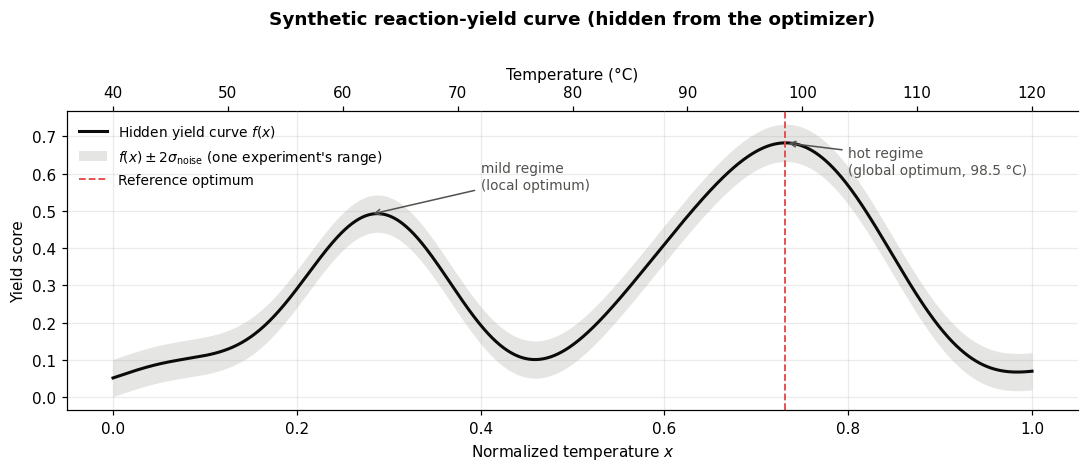

Reference optimum: 98.5 °C
Reference yield score: 0.6827


In [2]:
def objective_np(x):
    """
    Synthetic reaction-yield score as a function of normalized temperature.
    x can be a scalar, a 1D array, or a column array.
    This is a simulated benchmark, not real experimental data.
    """
    x = np.asarray(x, dtype=float)

    yield_score = (
        0.05
        + 0.42 * np.exp(-((x - 0.28) / 0.12)**2)   # a mild regime around 62 °C: a local optimum
        + 0.65 * np.exp(-((x - 0.72) / 0.15)**2)   # a hot regime around 98 °C: the global optimum
        + 0.03 * np.sin(8 * np.pi * x)             # small ripples: bumps that can trap a greedy search
    )

    return yield_score


# Dense reference grid for plotting and evaluating the known synthetic function
grid_np = np.linspace(0.0, 1.0, 1000)
true_y = objective_np(grid_np)

best_idx = np.argmax(true_y)
best_x_reference = grid_np[best_idx]
best_temperature_reference = to_celsius(best_x_reference)

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(grid_np, true_y, color=COLOR["truth"], lw=2, label="Hidden yield curve $f(x)$")
ax.fill_between(grid_np, true_y - 0.05, true_y + 0.05, color=COLOR["grey"], alpha=0.25, lw=0,
                label="$f(x) \\pm 2\\sigma_\\mathrm{noise}$ (one experiment's range)")
ax.axvline(best_x_reference, color=COLOR["obs"], ls="--", lw=1.2, label="Reference optimum")
ax.annotate("mild regime\n(local optimum)", xy=(0.28, objective_np(0.28)), xytext=(0.40, 0.56),
            arrowprops=dict(arrowstyle="->", color=COLOR["ink"]), fontsize=9, color=COLOR["ink"])
ax.annotate(f"hot regime\n(global optimum, {best_temperature_reference:.1f} °C)",
            xy=(best_x_reference, true_y[best_idx]), xytext=(0.80, 0.60),
            arrowprops=dict(arrowstyle="->", color=COLOR["ink"]), fontsize=9, color=COLOR["ink"])
ax.set_xlabel("Normalized temperature $x$")
ax.set_ylabel("Yield score")
ax.set_title("Synthetic reaction-yield curve (hidden from the optimizer)", pad=28)
sec = ax.secondary_xaxis("top", functions=(lambda x: 40 + 80 * x, lambda T: (T - 40) / 80))
sec.set_xlabel("Temperature (°C)")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

print(f"Reference optimum: {best_temperature_reference:.1f} °C")
print(f"Reference yield score: {true_y[best_idx]:.4f}")

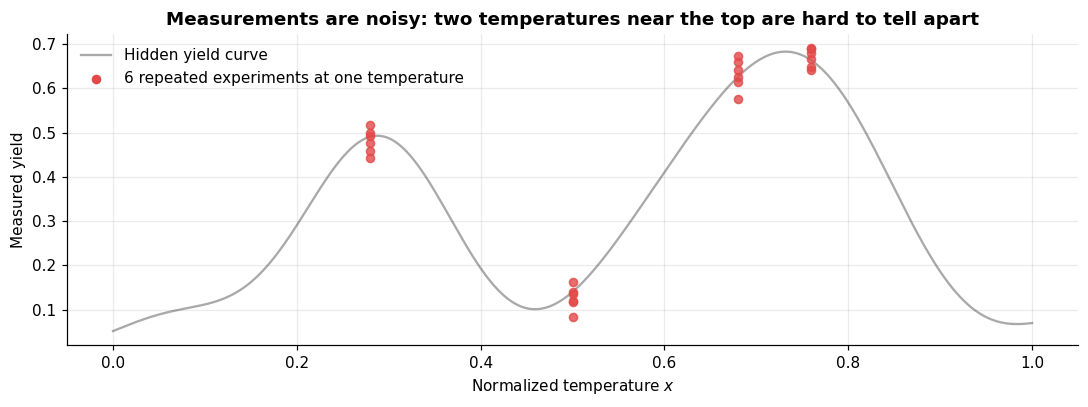

In [4]:
def oracle_with_rng(x, rng, noise_std=0.025):
    #🎯TODO Complete the oracle_with_rng function
    """
    Simulate one chemical reaction experiment.

    Parameters
    ----------
    x : float
        Normalized reaction temperature.
    rng : numpy random generator
        Controls reproducibility.
    noise_std : float
        Standard deviation of measurement noise.
    """
    true_yield = float(objective_np(x))
    #add random noise
    measured_yield = true_yield + rng.normal(0, noise_std)
    return float(measured_yield)



# What the chemist actually sees: repeated experiments at a few temperatures.
rng_demo = np.random.default_rng(SEED)
demo_x = np.array([0.28, 0.50, 0.68, 0.76])

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(grid_np, true_y, color=COLOR["truth"], lw=1.5, alpha=0.35, label="Hidden yield curve")
for xd in demo_x:
    ys = [oracle_with_rng(xd, rng_demo) for _ in range(6)]
    ax.scatter([xd] * 6, ys, s=28, color=COLOR["obs"], alpha=0.8, zorder=3)
ax.scatter([], [], s=28, color=COLOR["obs"], label="6 repeated experiments at one temperature")
ax.set_xlabel("Normalized temperature $x$")
ax.set_ylabel("Measured yield")
ax.set_title("Measurements are noisy: two temperatures near the top are hard to tell apart")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 2. Gaussian process surrogate in PyTorch

A Gaussian process (GP) is a probability distribution over functions. Before any experiment it says "the yield curve is smooth and of order one"; after $n$ experiments $(X, \mathbf{y})$ it says, for every candidate temperature $x_*$, how large the yield probably is **and how sure it is**:

$$
\mu(x_*) = \mathbf{k}_*^\top (K + \sigma_n^2 I)^{-1}\mathbf{y}, \qquad
\sigma^2(x_*) = k(x_*, x_*) - \mathbf{k}_*^\top (K + \sigma_n^2 I)^{-1}\mathbf{k}_* ,
$$

where $K_{ij} = k(x_i, x_j)$ is the covariance between two observed experiments, $\mathbf{k}_* = k(X, x_*)$ compares the candidate with them, and $\sigma_n$ is the measurement noise. The posterior mean $\mu$ interpolates the data; the posterior standard deviation $\sigma$ shrinks near observed temperatures and grows away from them.

The **kernel** $k$ encodes what "similar temperatures give similar yields" means. We implement four, all functions of the scaled distance $r = \|x - x'\| / \ell$ with lengthscale $\ell$:

| Kernel | $k(r)$ | Functions drawn from it are |
|---|---|---|
| RBF (squared exponential) | $\exp(-r^2/2)$ | infinitely smooth |
| Matérn 3/2 | $(1+\sqrt{3}\,r)\,e^{-\sqrt{3}\,r}$ | once differentiable, rougher |
| Matérn 5/2 | $(1+\sqrt{5}\,r+\tfrac{5}{3}r^2)\,e^{-\sqrt{5}\,r}$ | twice differentiable |
| Rational quadratic | $(1 + r^2/2\alpha)^{-\alpha}$ | a mixture of RBFs with many lengthscales |

The implementation is an **exact GP**: one Cholesky factorization of the $n \times n$ matrix $K + \sigma_n^2 I$, so the cost grows as $n^3$. That is practical for the experiment budgets below (a few dozen points); for thousands of observations one would switch to an approximate GP. Everything is written with `torch` tensors on `DEVICE`, and the same code handles inputs of any dimension: the bonus uses two.

In [7]:
def as_2d(x):
    """Return x as an [n, d] tensor: a scalar or a 1D array of n points becomes [n, 1]."""
    x = torch.as_tensor(x, dtype=DTYPE, device=DEVICE)
    if x.dim() == 0:
        return x.reshape(1, 1)
    if x.dim() == 1:
        return x.reshape(-1, 1)
    return x


def matern32_kernel(x1, x2, lengthscale=0.20, outputscale=1.0):
    #🎯TODO Complete the following code
    x1 = as_2d(x1)
    x2 = as_2d(x2)

    r = torch.cdist(x1 / lengthscale, x2 / lengthscale)
    #🎯TODO: Complete the following
    sqrt3_r = math.sqrt(3.0) * r
    #🎯TODO: Return the matern32 kernel computation
    return (1+sqrt3_r)*torch.exp(-sqrt3_r)


def matern52_kernel(x1, x2, lengthscale=0.20, outputscale=1.0):
    x1 = as_2d(torch.as_tensor(x1, dtype=DTYPE, device=DEVICE))
    x2 = as_2d(torch.as_tensor(x2, dtype=DTYPE, device=DEVICE))

    r = torch.cdist(x1 / lengthscale, x2 / lengthscale)
    sqrt5_r = math.sqrt(5.0) * r
    #🎯TODO: Return the matern52 kernel computation
    return (1+sqrt5_r)*torch.exp(-sqrt5_r)

def rational_quadratic_kernel(
    x1, x2, lengthscale=0.20, outputscale=1.0, alpha=1.0
):
    x1 = as_2d(torch.as_tensor(x1, dtype=DTYPE, device=DEVICE))
    x2 = as_2d(torch.as_tensor(x2, dtype=DTYPE, device=DEVICE))

    r2 = torch.cdist(x1 / lengthscale, x2 / lengthscale).square()
    #🎯TODO: Return the rational_quadratic_kernel
    return (1+r2/2/alpha)**(-alpha)

def rbf_kernel(x1, x2, lengthscale=0.20, outputscale=1.0):
    """RBF covariance: x1 [n,d], x2 [m,d] -> [n,m]."""
    x1 = as_2d(torch.as_tensor(x1, dtype=DTYPE, device=DEVICE))
    x2 = as_2d(torch.as_tensor(x2, dtype=DTYPE, device=DEVICE))
    sqdist = torch.cdist(x1 / lengthscale, x2 / lengthscale).square()
    #🎯TODO: Return the RBF kernel computation
    return torch.exp(-0.5*sqdist)


class ExactGP:
    def __init__(self, lengthscale=0.20, noise_std=0.025, jitter=1e-5,kernel="rbf"):
        self.lengthscale = lengthscale
        self.noise_std = noise_std
        self.jitter = jitter
        self.outputscale = 1.0
        self.kernel = kernel

    def covariance(self, X1, X2):
        kernels = {
            "rbf": rbf_kernel,
            "matern32": matern32_kernel,
            "matern52": matern52_kernel,
            "rq": rational_quadratic_kernel,
            }

        if self.kernel not in kernels:
            raise ValueError(f"Unknown kernel: {self.kernel}")

        return kernels[self.kernel](
            X1, X2, self.lengthscale, self.outputscale
        )

    def fit(self, X, y):
        self.X = torch.as_tensor(
            as_2d(X), dtype=DTYPE, device=DEVICE
        )
        self.y = torch.as_tensor(
            y, dtype=DTYPE, device=DEVICE
        ).reshape(-1, 1)

    # Check input consistency
        if len(self.X) != len(self.y):
            raise ValueError("X and y must have the same number of samples.")

        if not torch.isfinite(self.X).all():
            raise ValueError("X contains NaN or infinite values.")

        if not torch.isfinite(self.y).all():
            raise ValueError("y contains NaN or infinite values.")

        #🎯TODO: Compute covariance matrix
        K = self.covariance(self.X, self.X)

    # Enforce symmetry against floating-point errors
        K = 0.5 * (K + K.T)

    # Observation noise variance
        K = K + self.noise_std**2 * torch.eye(
            len(self.X), device=DEVICE, dtype=DTYPE
        )

    # Retry Cholesky with increasing jitter
        eye = torch.eye(len(self.X), device=DEVICE, dtype=DTYPE)
        jitter = self.jitter

        for attempt in range(7):
            try:
                self.L = torch.linalg.cholesky(K + jitter * eye)
                break
            except torch.linalg.LinAlgError:
                jitter *= 10
        else:
            raise RuntimeError(
                "Cholesky failed after increasing jitter. "
                "Check the covariance kernel and input data."
            )

        self.alpha = torch.cholesky_solve(self.y, self.L)
        return self

    @torch.no_grad()
    def predict(self, Xstar):
        Xstar = torch.as_tensor(as_2d(Xstar), dtype=DTYPE, device=DEVICE)
        #🎯TODO: Compute covariance matrix between the new point x start and a point x
        K_s = self.covariance(self.X, Xstar).T
        mean = K_s @ self.alpha
        v = torch.linalg.solve_triangular(self.L, K_s.T, upper=False)
        var = self.outputscale - v.square().sum(dim=0)
        return mean.squeeze(-1), var.clamp_min(1e-8).sqrt()




# Sanity check with one-dimensional inputs
X0 = np.linspace(0.05, 0.95, 5).reshape(-1, 1)

rng_check = np.random.default_rng(SEED)
y0 = objective_np(X0).reshape(-1)
y0 = y0 + rng_check.normal(0, 0.025, size=len(y0))

gp = ExactGP().fit(X0, y0)

# Predict over a one-dimensional candidate grid
X_test = np.linspace(0, 1, 100).reshape(-1, 1)
mu0, sd0 = gp.predict(X_test)

assert mu0.shape == (100,)
assert sd0.shape == (100,)
assert torch.isfinite(mu0).all()
assert torch.isfinite(sd0).all()
assert (sd0 >= 0).all()

print("1D GP sanity check passed.")
print("Posterior mean shape:", tuple(mu0.shape))
print("Posterior standard deviation shape:", tuple(sd0.shape))

1D GP sanity check passed.
Posterior mean shape: (100,)
Posterior standard deviation shape: (100,)


#### Watch the GP learn

Left to right: the prior (no experiment yet), then the posterior after 2, 4 and 8 experiments. The band is $\mu \pm 2\sigma$ and the thin lines are functions drawn from the GP: yield curves the model still considers plausible. The second row shows the same 8 experiments through the four kernels.

One detail to notice: the prior mean is $0$, so far from any experiment the posterior mean falls back towards $0$, below every yield the chemist will ever measure. Standardizing $\mathbf{y}$ before the fit, or a constant prior mean, would remove that artefact. We leave it in, because it makes the role of the prior visible.

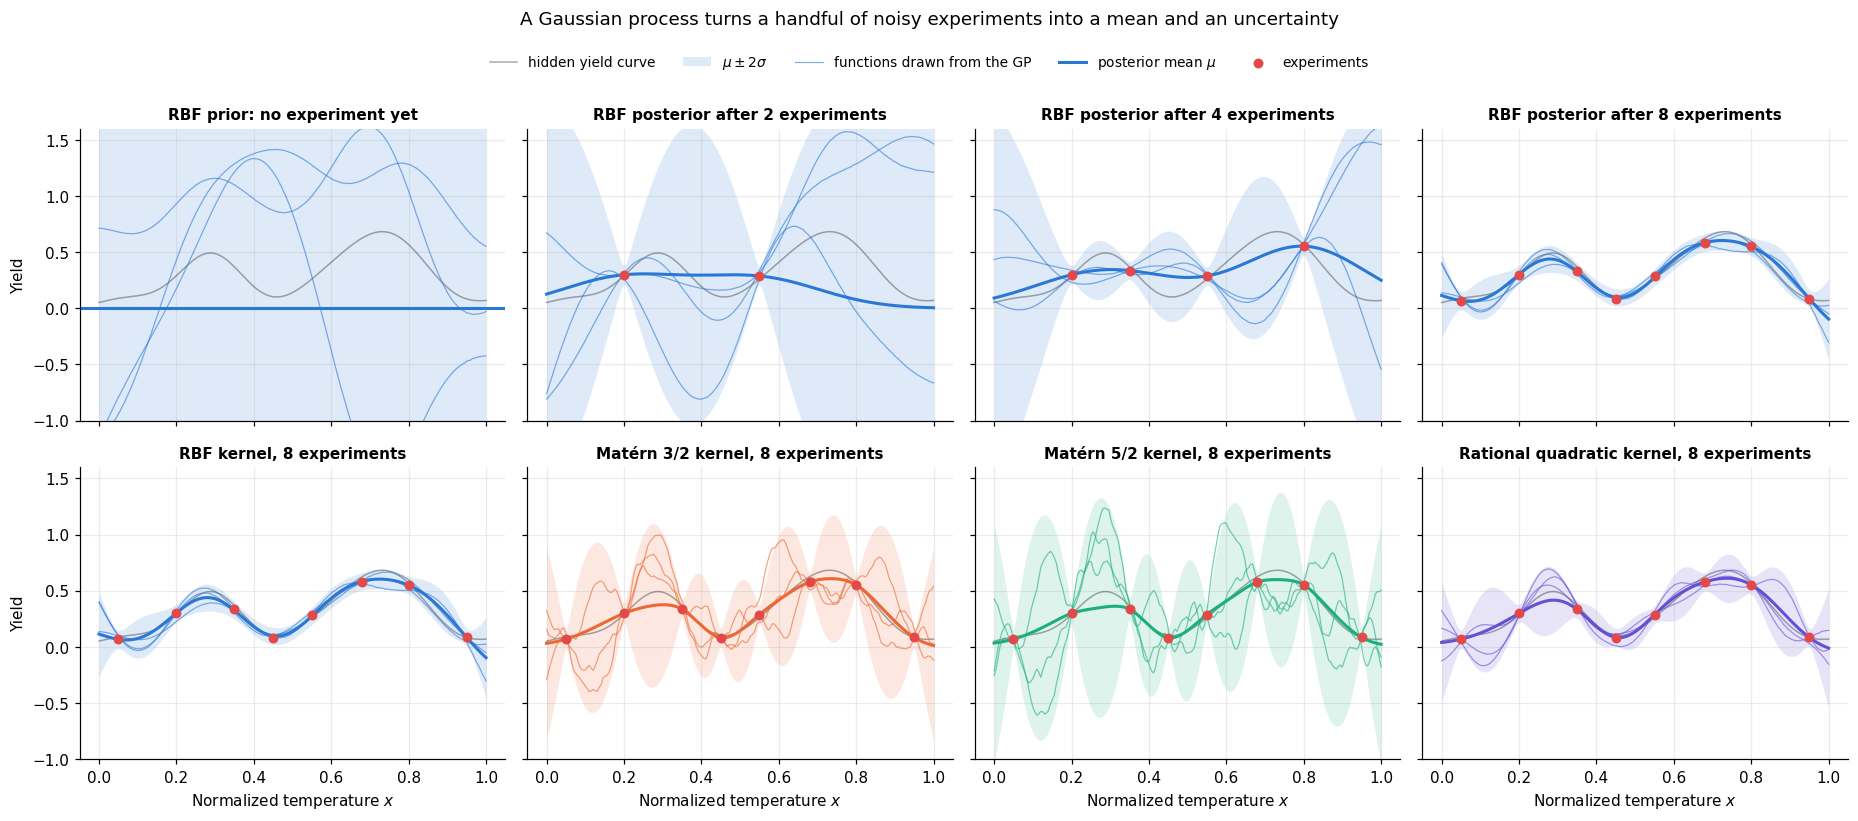

In [8]:
def gp_samples(gp, Xs, n_samples=3, seed=0):
    """Draw n_samples functions from the GP posterior on the points Xs (full predictive covariance)."""
    Xs_t = as_2d(Xs)
    K_s = gp.covariance(Xs_t, gp.X)
    K_ss = gp.covariance(Xs_t, Xs_t)
    v = torch.linalg.solve_triangular(gp.L, K_s.T, upper=False)
    mean = (K_s @ gp.alpha).squeeze(-1).cpu().double().numpy()
    cov = (K_ss - v.T @ v).cpu().double().numpy()
    w, V = np.linalg.eigh(0.5 * (cov + cov.T))           # robust to the near-singular covariance of a dense grid
    z = np.random.default_rng(seed).standard_normal((len(w), n_samples))
    return mean[:, None] + V @ (np.sqrt(np.clip(w, 0, None))[:, None] * z)

def gp_prior_samples(kernel_name, Xs, n_samples=3, lengthscale=0.16, seed=0):
    gp0 = ExactGP(lengthscale=lengthscale, kernel=kernel_name)
    K = gp0.covariance(as_2d(Xs), as_2d(Xs)).cpu().double().numpy()
    w, V = np.linalg.eigh(0.5 * (K + K.T))
    z = np.random.default_rng(seed).standard_normal((len(w), n_samples))
    return V @ (np.sqrt(np.clip(w, 0, None))[:, None] * z)

# A fixed order of experiments, so each panel adds to the previous one
demo_order = np.array([0.55, 0.20, 0.80, 0.35, 0.68, 0.95, 0.05, 0.45])
rng_learn = np.random.default_rng(SEED)
demo_y = np.array([oracle_with_rng(x, rng_learn) for x in demo_order])
Xs = np.linspace(0, 1, 200)

def draw_posterior(ax, gp, Xs, X_obs, y_obs, color, title):
    mu, sd = gp.predict(Xs)
    mu, sd = mu.cpu().numpy(), sd.cpu().numpy()
    ax.plot(grid_np, true_y, color=COLOR["truth"], lw=1, alpha=0.35, label="hidden yield curve")
    ax.fill_between(Xs, mu - 2 * sd, mu + 2 * sd, color=color, alpha=0.15, lw=0, label="$\\mu \\pm 2\\sigma$")
    for j, f in enumerate(gp_samples(gp, Xs).T):
        ax.plot(Xs, f, color=color, lw=0.8, alpha=0.6, label="functions drawn from the GP" if j == 0 else None)
    ax.plot(Xs, mu, color=color, lw=2, label="posterior mean $\\mu$")
    ax.scatter(X_obs, y_obs, s=30, color=COLOR["obs"], zorder=4, label="experiments")
    ax.set_title(title, fontsize=10)
    ax.set_ylim(-1.0, 1.6)

fig, axes = plt.subplots(2, 4, figsize=(17, 7), sharex=True, sharey=True)

# Row 1: the RBF GP as experiments accumulate
ax = axes[0, 0]
ax.plot(grid_np, true_y, color=COLOR["truth"], lw=1, alpha=0.35)
ax.fill_between(Xs, -2, 2, color=COLOR["rbf"], alpha=0.15, lw=0)
for f in gp_prior_samples("rbf", Xs).T:
    ax.plot(Xs, f, color=COLOR["rbf"], lw=0.8, alpha=0.6)
ax.axhline(0, color=COLOR["rbf"], lw=2)
ax.set_title("RBF prior: no experiment yet", fontsize=10)
for ax, n in zip(axes[0, 1:], [2, 4, 8]):
    gp_n = ExactGP(lengthscale=0.16, noise_std=0.04, kernel="rbf").fit(demo_order[:n], demo_y[:n])
    draw_posterior(ax, gp_n, Xs, demo_order[:n], demo_y[:n], COLOR["rbf"], f"RBF posterior after {n} experiments")

# Row 2: the same 8 experiments, four kernels
for ax, k in zip(axes[1], ["rbf", "matern32", "matern52", "rq"]):
    gp_k = ExactGP(lengthscale=0.16, noise_std=0.04, kernel=k).fit(demo_order, demo_y)
    draw_posterior(ax, gp_k, Xs, demo_order, demo_y, COLOR[k], f"{LABEL[k]} kernel, 8 experiments")

for ax in axes[1]:
    ax.set_xlabel("Normalized temperature $x$")
for ax in axes[:, 0]:
    ax.set_ylabel("Yield")
handles, labels = axes[0, 3].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.02), fontsize=9)
fig.suptitle("A Gaussian process turns a handful of noisy experiments into a mean and an uncertainty", y=1.06)
plt.tight_layout()
plt.show()

### 3. Acquisition functions: UCB and Expected Improvement

The GP gives a mean $\mu(x)$ and an uncertainty $\sigma(x)$ at every candidate temperature. An **acquisition function** turns the two numbers into one score, and the next experiment is the candidate with the highest score.

**Upper Confidence Bound: be optimistic.** Score each candidate by the best yield it could plausibly have,

$$\mathrm{UCB}(x) = \mu(x) + \kappa\,\sigma(x).$$

$\kappa$ sets the trade-off: $\kappa \to 0$ exploits (pick the highest mean); a large $\kappa$ explores (pick the most uncertain).

**Expected Improvement: bet on the gain.** Let $y^+$ be the best yield observed so far. Score each candidate by how much, on average, it would improve on $y^+$, counting a loss as zero:

$$\mathrm{EI}(x) = \mathbb{E}\big[\max(f(x) - y^+ - \xi,\,0)\big] = (\mu - y^+ - \xi)\,\Phi(z) + \sigma\,\phi(z), \qquad z = \frac{\mu - y^+ - \xi}{\sigma},$$

with $\Phi$ and $\phi$ the standard normal CDF and PDF, and a small $\xi$ that discourages tiny improvements. The first term rewards a high mean, the second rewards uncertainty. EI needs no $\kappa$: the data, through $y^+$, set the balance.

**Random search** ignores the GP and draws an untested candidate uniformly.

All three strategies receive the same initial experiments and the same evaluation budget.

In [9]:
def acquisition_ucb(mu, sd, kappa=2.0):
    # 🎯TODO: Return the Upper Confidence Bound (UCB) acquisition function.
    return mu + kappa*sd

# Expected Improvement: EI = (mu - best_y - xi) Phi(z) + sd phi(z).
def expected_improvement(mu, sd, best_y, xi=0.01):
    # 🎯TODO: Compute the expected improvement over the best observed value.
    improvement = mu - best_y - xi
    z = improvement / sd.clamp_min(1e-9)
    phi = torch.exp(-0.5*z.square()) / math.sqrt(2*math.pi)
    Phi = 0.5 * (1 + torch.erf(z / math.sqrt(2)))
    # 🎯TODO: Return the expected improvement
    return improvement * Phi + sd * phi

# Verify EI is finite and non-negative up to numerical precision.
test_ei = expected_improvement(mu0, sd0, float(np.max(y0)))
assert torch.isfinite(test_ei).all()
print("Acquisition functions ready.")

Acquisition functions ready.


#### Reading an acquisition function

Top: one GP posterior (the RBF model after the 8 experiments above). Below: the score each acquisition function gives to every candidate temperature, and the candidate it would test next (the star). A small $\kappa$ sends UCB back to the best-known region; a large $\kappa$ sends it to the least-explored one. EI is in units of yield gained and is nearly zero wherever the model is sure the yield is below $y^+$.

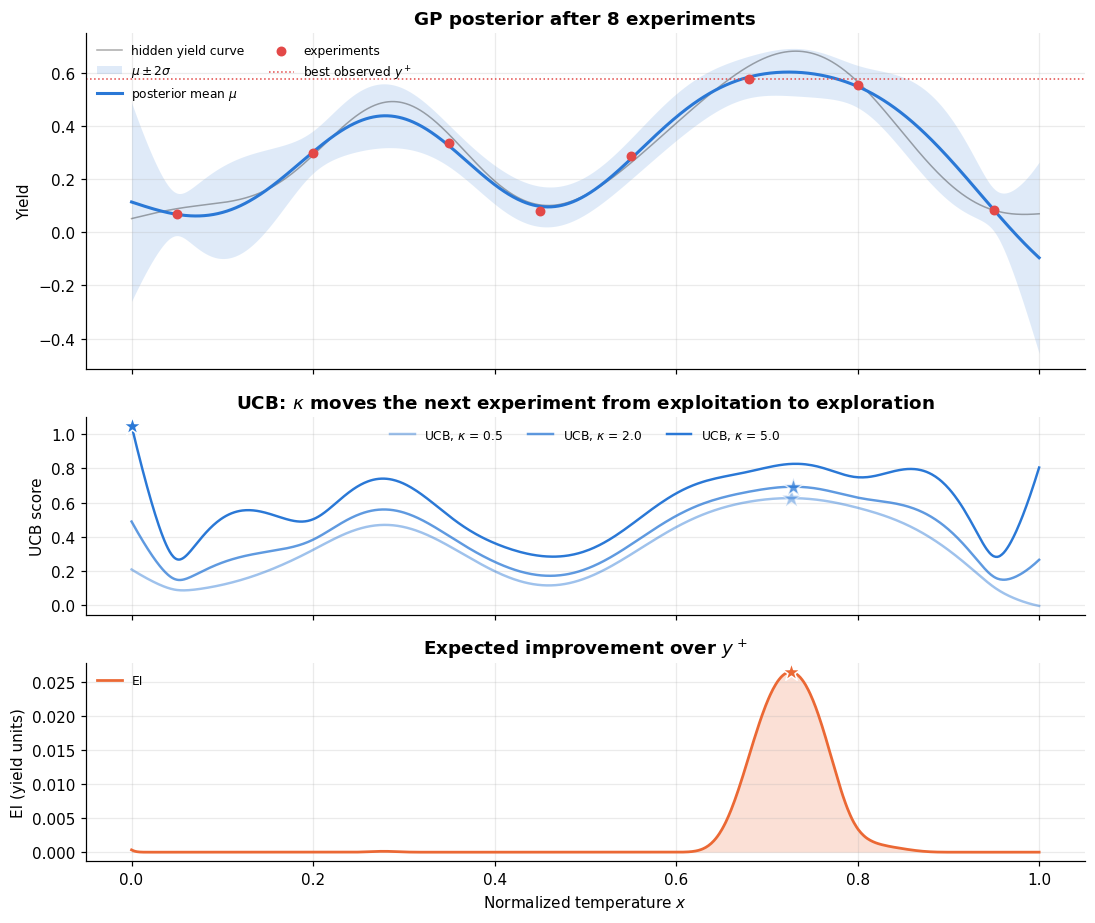

In [10]:
gp_demo = ExactGP(lengthscale=0.16, noise_std=0.04, kernel="rbf").fit(demo_order, demo_y)
mu_d, sd_d = gp_demo.predict(grid_np)
best_so_far = float(demo_y.max())

fig, axes = plt.subplots(3, 1, figsize=(10, 8.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1.3, 1.3]})

ax = axes[0]
mu_np, sd_np = mu_d.cpu().numpy(), sd_d.cpu().numpy()
ax.plot(grid_np, true_y, color=COLOR["truth"], lw=1, alpha=0.35, label="hidden yield curve")
ax.fill_between(grid_np, mu_np - 2 * sd_np, mu_np + 2 * sd_np, color=COLOR["rbf"], alpha=0.15, lw=0, label="$\\mu \\pm 2\\sigma$")
ax.plot(grid_np, mu_np, color=COLOR["rbf"], lw=2, label="posterior mean $\\mu$")
ax.scatter(demo_order, demo_y, s=30, color=COLOR["obs"], zorder=4, label="experiments")
ax.axhline(best_so_far, color=COLOR["obs"], ls=":", lw=1, label="best observed $y^+$")
ax.set_ylabel("Yield")
ax.set_title("GP posterior after 8 experiments")
ax.legend(loc="upper left", fontsize=8, ncol=2)

ax = axes[1]
for kappa, alpha in [(0.5, 0.45), (2.0, 0.75), (5.0, 1.0)]:
    score = acquisition_ucb(mu_d, sd_d, kappa=kappa).cpu().numpy()
    ax.plot(grid_np, score, color=COLOR["ucb"], lw=1.6, alpha=alpha, label=f"UCB, $\\kappa$ = {kappa}")
    i = int(np.argmax(score))
    ax.scatter([grid_np[i]], [score[i]], marker="*", s=160, color=COLOR["ucb"], alpha=alpha, zorder=4, edgecolor="white")
ax.set_ylabel("UCB score")
ax.set_title("UCB: $\\kappa$ moves the next experiment from exploitation to exploration")
ax.legend(loc="upper center", fontsize=8, ncol=3)

ax = axes[2]
score = expected_improvement(mu_d, sd_d, best_so_far).cpu().numpy()
ax.fill_between(grid_np, 0, score, color=COLOR["ei"], alpha=0.2, lw=0)
ax.plot(grid_np, score, color=COLOR["ei"], lw=1.8, label="EI")
i = int(np.argmax(score))
ax.scatter([grid_np[i]], [score[i]], marker="*", s=160, color=COLOR["ei"], zorder=4, edgecolor="white")
ax.set_ylabel("EI (yield units)")
ax.set_xlabel("Normalized temperature $x$")
ax.set_title("Expected improvement over $y^+$")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

### 4. Run Bayesian optimization

The loop below starts from **10 initial experiments** spread evenly over the temperature range, then performs **50 sequential queries**. At each step it

1. fits the GP to all experiments so far;
2. scores a candidate grid of 1,000 temperatures (scoring the grid is computation, not laboratory work);
3. discards candidates within $0.008$ of a temperature already tested, so the loop does not re-measure the same point;
4. runs the experiment with the highest score and adds it to the data.

We compare UCB, EI and random search with the same initial design and the same total number of experiments, for each of the four kernels.

**Two ways to answer "which temperature do we recommend?"** The loop records both, and the difference matters below.

- **Best observed:** the temperature whose *measured* yield was the highest. Simple, but a measurement includes noise, so the winner is partly the experiment that drew the luckiest noise.
- **GP recommendation:** the temperature where the GP's *posterior mean* is highest. The GP averages the noise out.

For evaluation only, we look up the *true* yield of each answer in the hidden function. The **simple regret** is the gap between the true optimum and that value.

In [11]:
def run_bo(method="ucb", n_init=10, n_steps=50, seed=0, kappa=2.0,
           kernel="rbf", lengthscale=0.16, noise_std=0.04):
    rng = np.random.default_rng(seed)

    # Initial experiments, spread across the temperature range
    X = np.linspace(0.02, 0.98, n_init)
    y = np.array([oracle_with_rng(x, rng) for x in X])

    # Candidate temperatures for acquisition-function optimization
    candidate_grid = np.linspace(0.0, 1.0, 1000)

    def fit_and_predict(X, y):
        #🎯TODO: Fit the exact gp
        gp = ExactGP(lengthscale=lengthscale, noise_std=noise_std, kernel=kernel).fit(X, y)
        # Predict the GP posterior
        return gp.predict(candidate_grid)

    history_best_true = []   # true yield at the best *observed* temperature
    history_rec_true = []    # true yield at the GP's *recommended* temperature (argmax of the posterior mean)
    queried = []

    mu, sd = fit_and_predict(X, y)
    for step in range(n_steps):
        # Choose the next temperature
        if method == "ucb":
            #🎯TODO: Define the score
            score = acquisition_ucb(mu, sd, kappa=kappa)
        elif method == "ei":
            #🎯TODO: Define the score
            score = expected_improvement(mu, sd, np.max(y), xi=0.01)
        elif method == "random":
            #🎯TODO: Define the score
            score = rng.uniform(size=len(candidate_grid))
        else:
            raise ValueError("method must be 'ucb', 'ei', or 'random'")

        # Convert acquisition values to NumPy for candidate selection
        if torch.is_tensor(score):
            score_np = score.detach().cpu().numpy().reshape(-1).copy()
        else:
            score_np = np.asarray(score).reshape(-1).copy()

        # Avoid repeatedly testing almost identical temperatures
        score_np[np.abs(candidate_grid[:, None] - X[None, :]).min(axis=1) < 0.008] = -np.inf

        # Select the best remaining candidate and perform the simulated experiment
        x_next = float(candidate_grid[np.argmax(score_np)])
        y_next = oracle_with_rng(x_next, rng)

        X = np.append(X, x_next)
        y = np.append(y, y_next)
        queried.append(x_next)

        # Refit with the new experiment: this posterior is used for the next step and for the recommendation
        mu, sd = fit_and_predict(X, y)

        best_idx = int(np.argmax(y))
        history_best_true.append(float(objective_np(X[best_idx])))
        rec_idx = int(torch.argmax(mu))
        history_rec_true.append(float(objective_np(candidate_grid[rec_idx])))

    best_idx = int(np.argmax(y))
    rec_idx = int(torch.argmax(mu))

    return {
        "X": X,
        "y": y,
        "queried": np.array(queried),
        "best_x": float(X[best_idx]),
        "best_observed": float(y[best_idx]),
        "best_true": float(objective_np(X[best_idx])),
        "best_true_history": np.array(history_best_true),
        "rec_x": float(candidate_grid[rec_idx]),
        "rec_true": float(objective_np(candidate_grid[rec_idx])),
        "rec_true_history": np.array(history_rec_true),
    }


# Compare all GP kernels and acquisition methods on one seed
kernels = ["rbf", "matern32", "matern52", "rq"]
methods = ["ucb", "ei", "random"]
N_INIT, N_STEPS = 10, 50

results = {}
for kernel_name in kernels:
    for method in methods:
        results[f"{kernel_name}_{method}"] = run_bo(
            method=method, n_init=N_INIT, n_steps=N_STEPS, seed=100,
            kappa=2.0, kernel=kernel_name, lengthscale=0.16,
        )

print("=== One run per kernel and acquisition method (seed 100) ===")
print(f"{'Kernel':10s} | {'Method':8s} | {'best observed':>24s} | {'GP recommendation':>24s}")
print(f"{'':10s} | {'':8s} | {'temp.':>8s} {'true yield':>15s} | {'temp.':>8s} {'true yield':>15s}")
for kernel_name in kernels:
    for method in methods:
        res = results[f"{kernel_name}_{method}"]
        print(f"{LABEL[kernel_name]:10s} | {LABEL[method]:8s} | "
              f"{to_celsius(res['best_x']):6.1f} °C {res['best_true']:15.4f} | "
              f"{to_celsius(res['rec_x']):6.1f} °C {res['rec_true']:15.4f}")
print(f"\nTrue optimum: {best_temperature_reference:.1f} °C, yield {true_y.max():.4f}")

=== One run per kernel and acquisition method (seed 100) ===
Kernel     | Method   |            best observed |        GP recommendation
           |          |    temp.      true yield |    temp.      true yield
RBF        | UCB      |   97.8 °C          0.6808 |   98.4 °C          0.6826
RBF        | EI       |   97.8 °C          0.6808 |   98.1 °C          0.6821
RBF        | Random search |   98.2 °C          0.6823 |   98.9 °C          0.6824
Matérn 3/2 | UCB      |   97.3 °C          0.6767 |   97.4 °C          0.6781
Matérn 3/2 | EI       |   97.5 °C          0.6787 |   97.3 °C          0.6774
Matérn 3/2 | Random search |   98.2 °C          0.6823 |   98.9 °C          0.6824
Matérn 5/2 | UCB      |   97.2 °C          0.6759 |   97.2 °C          0.6759
Matérn 5/2 | EI       |   97.4 °C          0.6781 |   97.3 °C          0.6767
Matérn 5/2 | Random search |   98.2 °C          0.6823 |   98.6 °C          0.6827
Rational quadratic | UCB      |   97.6 °C          0.6793 |   98.5 °C 

#### Watch UCB work

Four snapshots of the RBF + UCB run. Top: the posterior after 10, 11, 15 and 30 experiments. Bottom: the UCB score over the candidates at that moment; the star is the experiment the loop ran next. Early on the uncertainty term dominates and UCB fills the gaps; once the band is narrow everywhere, it settles on the hot regime and refines it. By the 30th experiment the peak is sampled so densely that the exclusion rule (no new experiment within $0.008$ of an old one) pushes the next query to the flank of the peak: the star no longer sits on the maximum of the UCB curve.

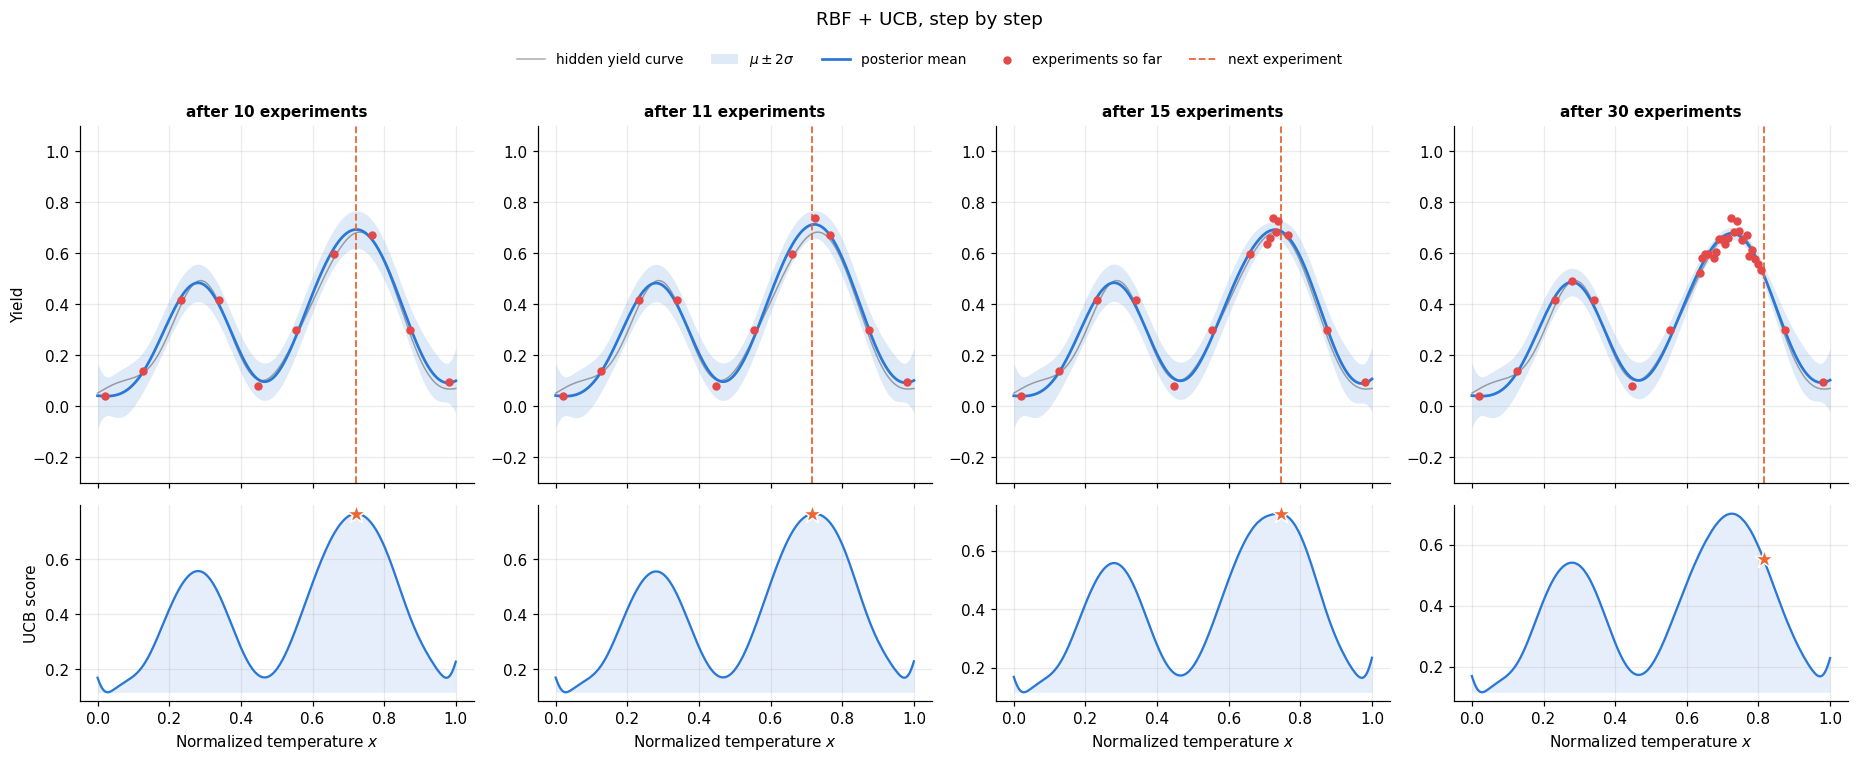

In [12]:
res = results["rbf_ucb"]
snapshots = [0, 1, 5, 20]   # number of queries already made after the initial design

fig, axes = plt.subplots(2, 4, figsize=(17, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1.1]})
for col, k in enumerate(snapshots):
    X_k, y_k = res["X"][:N_INIT + k], res["y"][:N_INIT + k]
    gp_k = ExactGP(lengthscale=0.16, noise_std=0.04, kernel="rbf").fit(X_k, y_k)
    mu_k, sd_k = gp_k.predict(grid_np)
    score_k = acquisition_ucb(mu_k, sd_k, kappa=2.0).cpu().numpy()
    mu_k, sd_k = mu_k.cpu().numpy(), sd_k.cpu().numpy()
    x_next = res["X"][N_INIT + k]

    ax = axes[0, col]
    ax.plot(grid_np, true_y, color=COLOR["truth"], lw=1, alpha=0.35, label="hidden yield curve")
    ax.fill_between(grid_np, mu_k - 2 * sd_k, mu_k + 2 * sd_k, color=COLOR["ucb"], alpha=0.15, lw=0, label="$\\mu \\pm 2\\sigma$")
    ax.plot(grid_np, mu_k, color=COLOR["ucb"], lw=1.8, label="posterior mean")
    ax.scatter(X_k, y_k, s=20, color=COLOR["obs"], zorder=3, label="experiments so far")
    ax.axvline(x_next, color=COLOR["ei"], ls="--", lw=1.2, label="next experiment")
    ax.set_title(f"after {N_INIT + k} experiments", fontsize=10)
    ax.set_ylim(-0.3, 1.1)

    ax = axes[1, col]
    ax.fill_between(grid_np, score_k.min(), score_k, color=COLOR["ucb"], alpha=0.12, lw=0)
    ax.plot(grid_np, score_k, color=COLOR["ucb"], lw=1.5)
    ax.scatter([x_next], [score_k[np.argmin(np.abs(grid_np - x_next))]], marker="*", s=170,
               color=COLOR["ei"], zorder=4, edgecolor="white")
    ax.set_xlabel("Normalized temperature $x$")

axes[0, 0].set_ylabel("Yield")
axes[1, 0].set_ylabel("UCB score")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.02), fontsize=9)
fig.suptitle("RBF + UCB, step by step", y=1.06)
plt.tight_layout()
plt.show()

#### Every experiment, in the order it was run

For each strategy (RBF kernel, the same seed): the measured yield of experiment 1 to 60 as dots, the true yield of that temperature as a line, and the best observed experiment ringed. The first 10 experiments are the shared initial design. UCB spends its queries near the top of the curve and, once the peak is crowded, walks down its flanks; random search keeps sampling the whole range.

EI does something odd in its last twenty experiments: it goes to the lowest-yield corner of the range. The reason is instructive. Its incumbent $y^+$ is the best *measured* yield, which the noise has inflated above the true maximum (experiment 11 measured $0.74$ where the curve never exceeds $0.68$). Nothing near the peak can be expected to beat that number, so EI is left with the regions where the uncertainty is largest, the edges. For noisy objectives the standard fix is to take the maximum of the posterior mean as the incumbent.

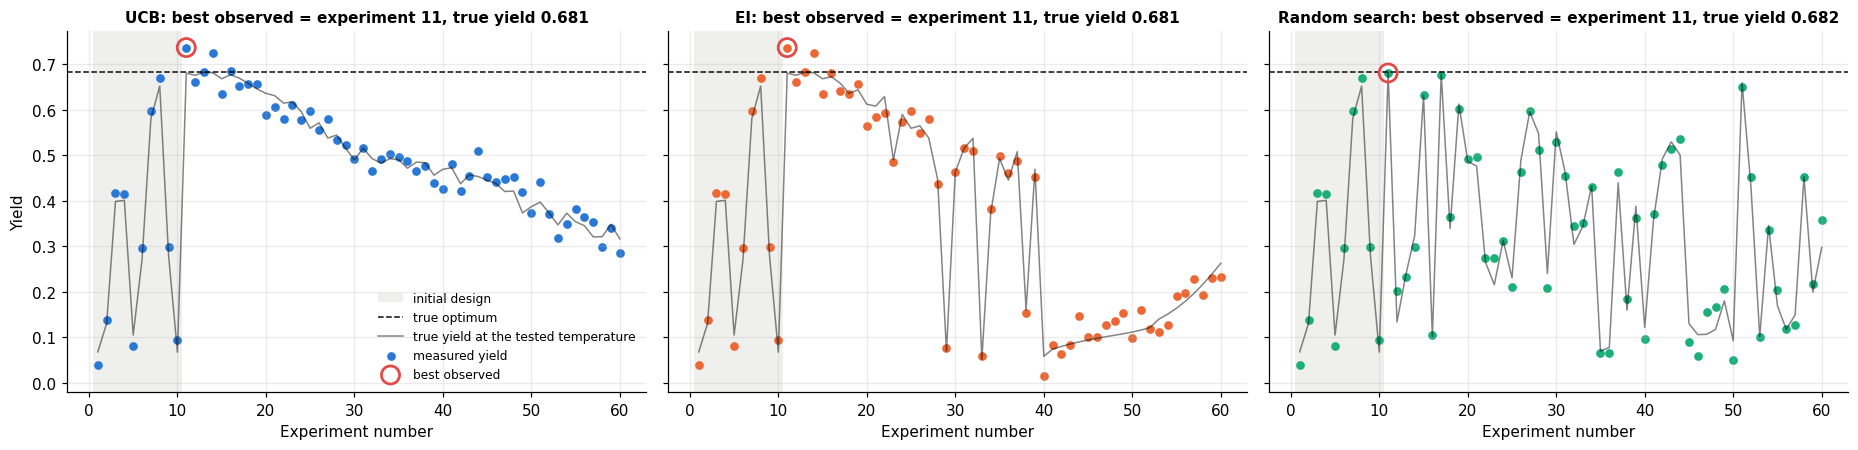

First 12 experiments of the random-search run (RBF):
  01 |  41.60 °C | measured 0.0394 | true 0.0683
  02 |  50.13 °C | measured 0.1381 | true 0.1308
  03 |  58.67 °C | measured 0.4184 | true 0.3989
  04 |  67.20 °C | measured 0.4149 | true 0.4013
  05 |  75.73 °C | measured 0.0813 | true 0.1053
  06 |  84.27 °C | measured 0.2975 | true 0.2707
  07 |  92.80 °C | measured 0.5983 | true 0.5808
  08 | 101.33 °C | measured 0.6699 | true 0.6522
  09 | 109.87 °C | measured 0.2985 | true 0.2799
  10 | 118.40 °C | measured 0.0954 | true 0.0678
  11 |  98.22 °C | measured 0.6811 | true 0.6823
  12 |  79.72 °C | measured 0.2011 | true 0.1342


In [13]:
f_max = float(true_y.max())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
for ax, method in zip(axes, methods):
    res = results[f"rbf_{method}"]
    n = np.arange(1, len(res["X"]) + 1)
    true_at_X = objective_np(res["X"])
    ax.axvspan(0.5, N_INIT + 0.5, color=COLOR["grey"], alpha=0.15, lw=0, label="initial design")
    ax.axhline(f_max, color=COLOR["truth"], ls="--", lw=1, label="true optimum")
    ax.plot(n, true_at_X, color=COLOR["truth"], lw=1, alpha=0.5, label="true yield at the tested temperature")
    ax.scatter(n, res["y"], s=22, color=COLOR[method], label="measured yield")
    b = int(np.argmax(res["y"]))
    ax.scatter([n[b]], [res["y"][b]], s=140, facecolor="none", edgecolor=COLOR["obs"], lw=1.8, zorder=4, label="best observed")
    ax.set_title(f"{LABEL[method]}: best observed = experiment {n[b]}, true yield {res['best_true']:.3f}", fontsize=10)
    ax.set_xlabel("Experiment number")
axes[0].set_ylabel("Yield")
axes[0].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

print("First 12 experiments of the random-search run (RBF):")
res = results["rbf_random"]
for i in range(12):
    print(f"  {i + 1:02d} | {to_celsius(res['X'][i]):6.2f} °C | measured {res['y'][i]:.4f} | true {objective_np(res['X'][i]):.4f}")

In [14]:
print(f"{'Method':14s} | {'best observed':>30s} | {'GP recommendation':>30s}")
print(f"{'':14s} | {'temp.':>8s} {'true yield':>10s} {'regret':>9s} | {'temp.':>8s} {'true yield':>10s} {'regret':>9s}")
for method in ["random", "ucb", "ei"]:
    res = results[f"rbf_{method}"]
    print(f"{LABEL[method]:14s} | {to_celsius(res['best_x']):6.1f} °C {res['best_true']:10.4f} {f_max - res['best_true']:9.4f} | "
          f"{to_celsius(res['rec_x']):6.1f} °C {res['rec_true']:10.4f} {f_max - res['rec_true']:9.4f}")
print(f"\nNoise standard deviation of one experiment: 0.025")

Method         |                  best observed |              GP recommendation
               |    temp. true yield    regret |    temp. true yield    regret
Random search  |   98.2 °C     0.6823    0.0004 |   98.9 °C     0.6824    0.0004
UCB            |   97.8 °C     0.6808    0.0019 |   98.4 °C     0.6826    0.0001
EI             |   97.8 °C     0.6808    0.0019 |   98.1 °C     0.6821    0.0006

Noise standard deviation of one experiment: 0.025


#### A puzzle: did random search just beat Bayesian optimization?

Under "best observed", this single run can rank random search **above** UCB. Before explaining it, look at the sizes: every answer is within about $0.01$ of the optimum, less than half the noise standard deviation of one experiment ($0.025$). Three things are going on, and the next cell measures each.

1. **One seed is one coin flip.** Every run above used `seed=100`. Random search drew a lucky sequence. A ranking needs many seeds.
2. **"Best observed" suffers from the winner's curse.** Each measurement is $f(x) + \varepsilon$. The experiment with the highest *measured* yield is the one that combined a high $f(x)$ with a lucky $\varepsilon$. The more experiments you run near the peak, the more lottery tickets you hold, and the winner is a near-optimal temperature with a large positive noise rather than the optimum itself. BO clusters its experiments at the peak, so it holds the most tickets and is punished the most by this metric. The GP recommendation averages the noise out and does not have the problem.
3. **The problem is too easy to separate the strategies.** Ten evenly spaced initial experiments already pin a curve this smooth, and 60 experiments on an interval put a point every $0.017$ on average, so random search cannot miss a peak of width $0.15$. BO's advantage shows with a sparser start and with more knobs (see the bonus).

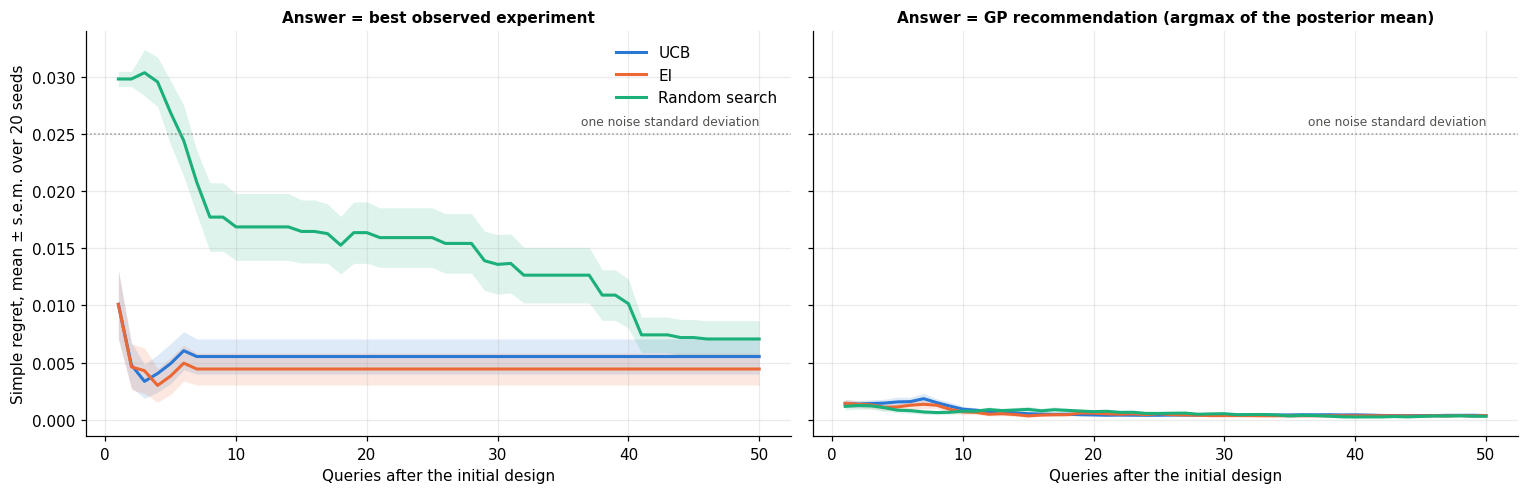

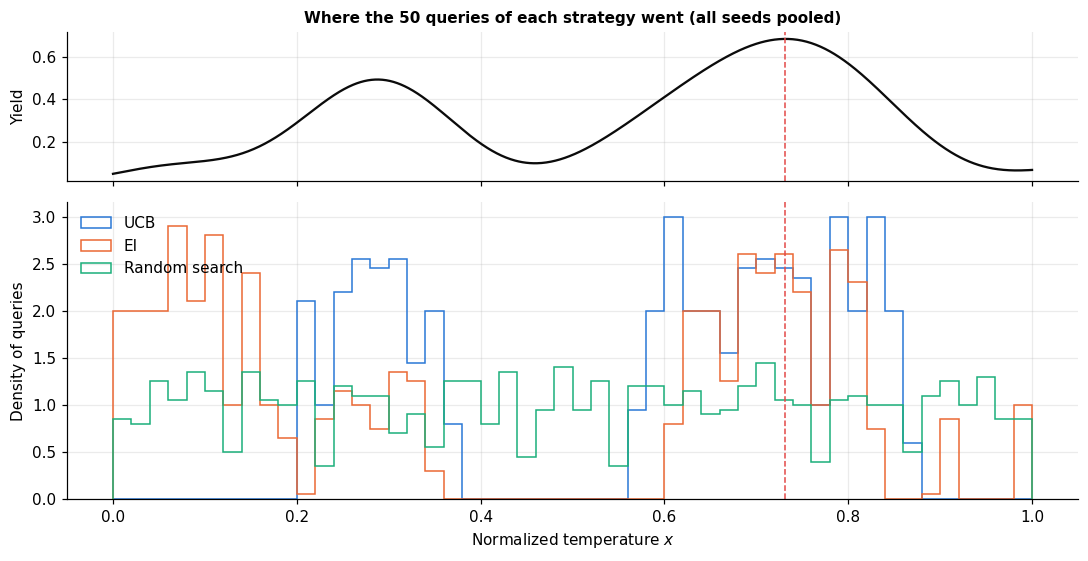

Mean simple regret over 20 seeds (RBF kernel)
Method         | answer             | after  5 | after 10 | after 20 | after 50
UCB            | best observed      |   0.0049 |   0.0055 |   0.0055 |   0.0055
UCB            | GP recommendation  |   0.0016 |   0.0009 |   0.0004 |   0.0004
EI             | best observed      |   0.0038 |   0.0044 |   0.0044 |   0.0044
EI             | GP recommendation  |   0.0011 |   0.0007 |   0.0006 |   0.0004
Random search  | best observed      |   0.0269 |   0.0169 |   0.0164 |   0.0071
Random search  | GP recommendation  |   0.0008 |   0.0007 |   0.0007 |   0.0003

UCB           :   21% of queries within ±0.05 (±4 °C) of the optimum
EI            :   21% of queries within ±0.05 (±4 °C) of the optimum
Random search :   10% of queries within ±0.05 (±4 °C) of the optimum


In [15]:
N_SEEDS_BO = 20
seeds_bo = range(N_SEEDS_BO)

multi = {m: [run_bo(method=m, n_init=N_INIT, n_steps=N_STEPS, seed=s, kernel="rbf") for s in seeds_bo] for m in methods}
regret_obs = {m: f_max - np.stack([r["best_true_history"] for r in runs]) for m, runs in multi.items()}
regret_rec = {m: f_max - np.stack([r["rec_true_history"] for r in runs]) for m, runs in multi.items()}
steps = np.arange(1, N_STEPS + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, (title, regret) in zip(axes, [("Answer = best observed experiment", regret_obs),
                                       ("Answer = GP recommendation (argmax of the posterior mean)", regret_rec)]):
    for m in methods:
        mean, sem = regret[m].mean(0), regret[m].std(0) / np.sqrt(N_SEEDS_BO)
        ax.plot(steps, mean, color=COLOR[m], lw=2, label=LABEL[m])
        ax.fill_between(steps, mean - sem, mean + sem, color=COLOR[m], alpha=0.15, lw=0)
    ax.axhline(0.025, color=COLOR["grey"], ls=":", lw=1)
    ax.text(N_STEPS, 0.0255, "one noise standard deviation", ha="right", va="bottom", fontsize=8, color=COLOR["ink"])
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Queries after the initial design")
axes[0].set_ylabel(f"Simple regret, mean ± s.e.m. over {N_SEEDS_BO} seeds")
axes[0].legend()
plt.tight_layout()
plt.show()

# Where did the experiments go?
fig, axes = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
axes[0].plot(grid_np, true_y, color=COLOR["truth"], lw=1.5)
axes[0].axvline(best_x_reference, color=COLOR["obs"], ls="--", lw=1)
axes[0].set_ylabel("Yield")
axes[0].set_title("Where the 50 queries of each strategy went (all seeds pooled)", fontsize=10)
bins = np.linspace(0, 1, 51)
for m in methods:
    xs = np.concatenate([r["queried"] for r in multi[m]])
    axes[1].hist(xs, bins=bins, density=True, histtype="step", lw=2, color=COLOR[m], label=LABEL[m])
axes[1].axvline(best_x_reference, color=COLOR["obs"], ls="--", lw=1)
axes[1].set_ylabel("Density of queries")
axes[1].set_xlabel("Normalized temperature $x$")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"Mean simple regret over {N_SEEDS_BO} seeds (RBF kernel)")
print(f"{'Method':14s} | {'answer':18s} | " + " | ".join(f"after {k:2d}" for k in [5, 10, 20, 50]))
for m in methods:
    for name, regret in [("best observed", regret_obs), ("GP recommendation", regret_rec)]:
        print(f"{LABEL[m]:14s} | {name:18s} | " + " | ".join(f"{regret[m][:, k - 1].mean():8.4f}" for k in [5, 10, 20, 50]))
print()
for m in methods:
    xs = np.concatenate([r["queried"] for r in multi[m]])
    near = np.mean(np.abs(xs - best_x_reference) < 0.05)
    print(f"{LABEL[m]:14s}: {100 * near:4.0f}% of queries within ±0.05 (±4 °C) of the optimum")

**Verdict.** Averaged over 20 seeds the ranking of the single run is reversed: under "best observed", UCB and EI have a regret 5 to 7 times smaller than random search at every budget. Their curve is flat at about $0.004$ from the fifth query on, and that floor *is* the winner's curse: the right panel shows the same runs within $0.001$ of the optimum as soon as the answer is the GP's recommendation. In the right panel all three strategies are near the optimum from the first query, because the 10 evenly spaced initial experiments already pin a curve this smooth. In one dimension the initial design, not the acquisition function, solves the problem; BO has to show its advantage with more knobs, which is what the bonus does.

The histogram shows where the best-observed bias comes from: BO puts about a fifth of its queries within $\pm 4^\circ\mathrm{C}$ of the optimum, random search a tenth, so BO holds twice as many tickets in the noise lottery. It also shows EI's excursions to the left edge, the effect of its inflated incumbent discussed above.

Three rules follow: report the model's recommendation, not the best measurement; average over seeds; and compare at the budget you can actually afford.

#### Does the kernel matter?

The same seed through the four kernels. Top: every experiment of each run against the hidden curve, with the best observed temperature and the GP's recommendation. Bottom: the regret of the GP recommendation along the run. On this smooth, well-sampled curve the four kernels agree; the choice matters more when the data are scarce or the function is rough.

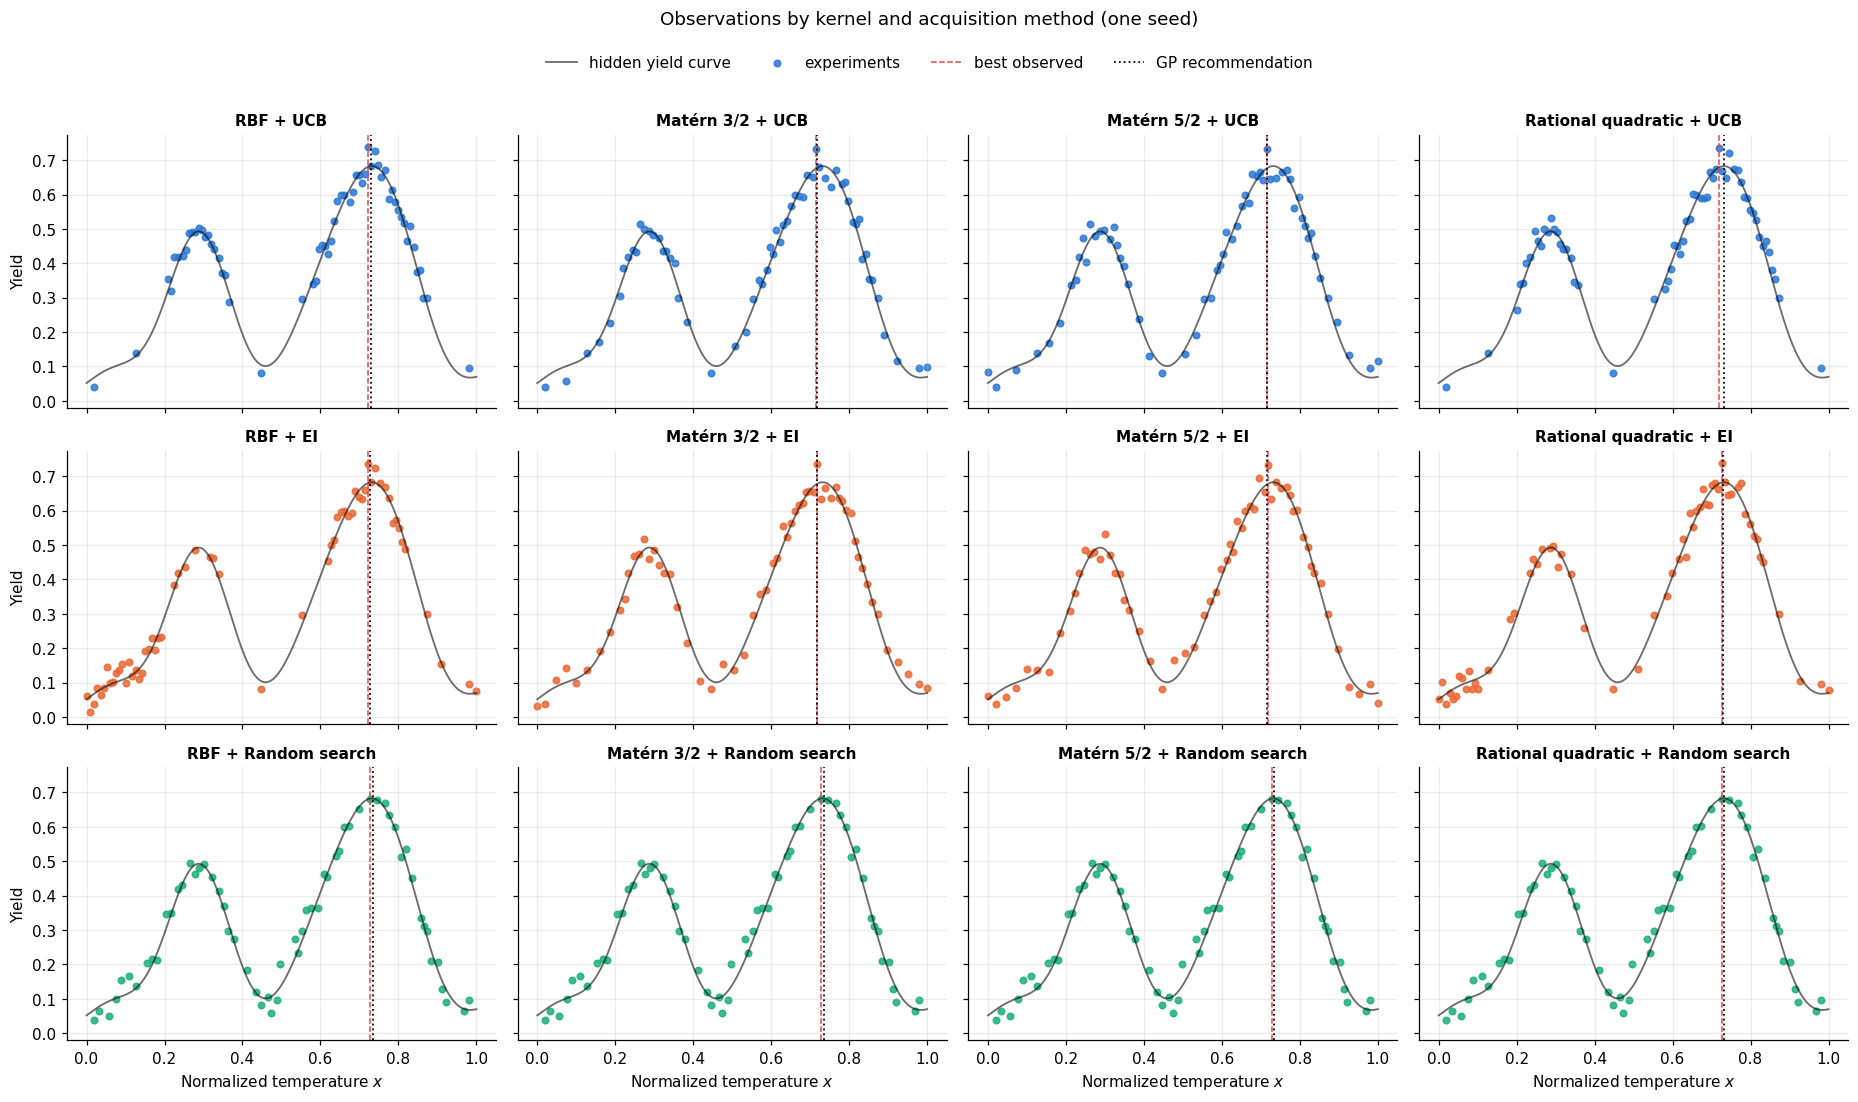

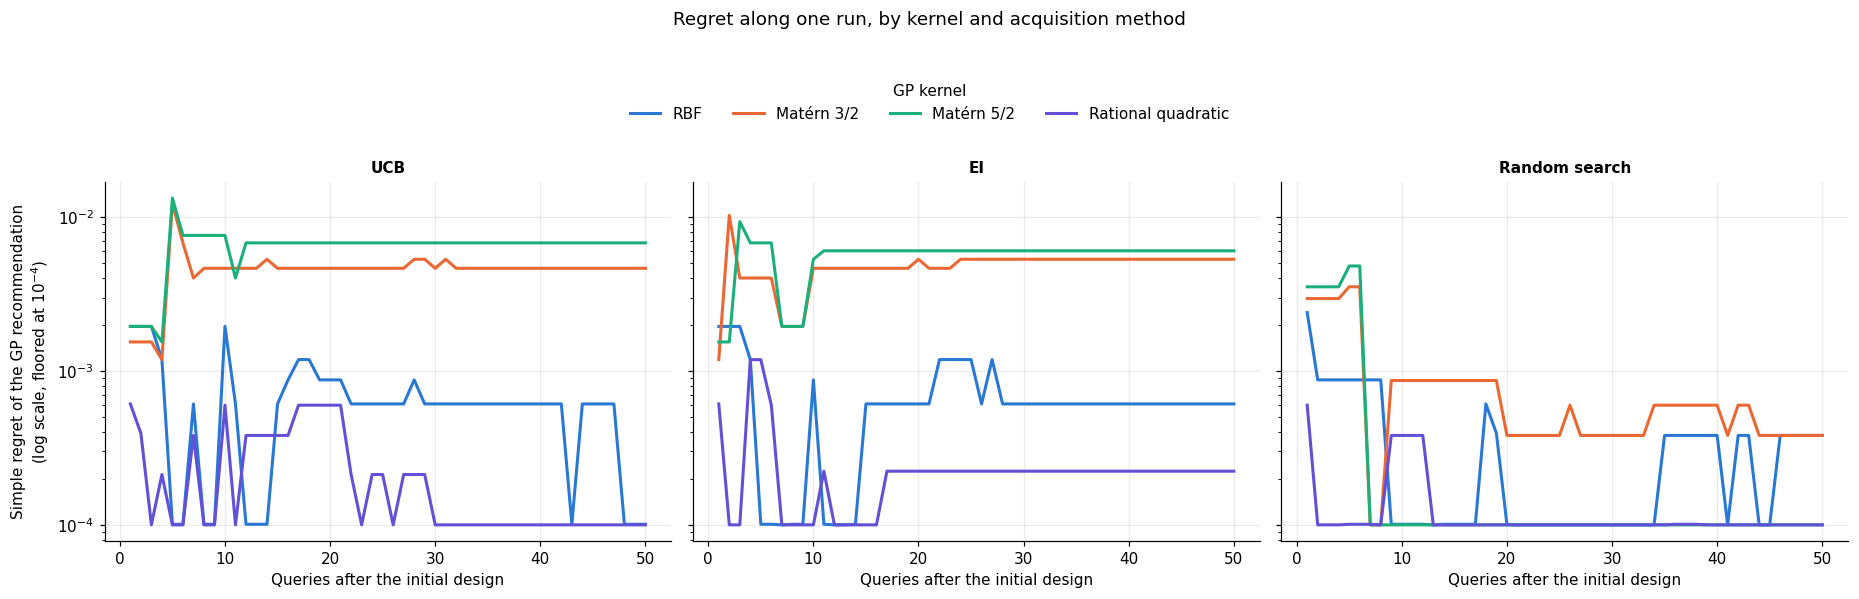

In [16]:
fig, axes = plt.subplots(3, 4, figsize=(17, 9.5), sharey=True, sharex=True)
for row, method in enumerate(methods):
    for col, kernel_name in enumerate(kernels):
        ax = axes[row, col]
        res = results[f"{kernel_name}_{method}"]
        ax.plot(grid_np, true_y, color=COLOR["truth"], lw=1.2, alpha=0.6, label="hidden yield curve")
        ax.scatter(res["X"], res["y"], s=18, color=COLOR[method], alpha=0.85, label="experiments")
        ax.axvline(res["best_x"], color=COLOR["obs"], ls="--", lw=1, label="best observed")
        ax.axvline(res["rec_x"], color=COLOR["truth"], ls=":", lw=1.2, label="GP recommendation")
        ax.set_title(f"{LABEL[kernel_name]} + {LABEL[method]}", fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel("Normalized temperature $x$")
for ax in axes[:, 0]:
    ax.set_ylabel("Yield")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Observations by kernel and acquisition method (one seed)", y=1.05)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, method in zip(axes, methods):
    for kernel_name in kernels:
        res = results[f"{kernel_name}_{method}"]
        regret = np.maximum(1e-4, f_max - res["rec_true_history"])   # floored at the resolution of the candidate grid
        ax.plot(steps, regret, color=COLOR[kernel_name], lw=2, label=LABEL[kernel_name])
    ax.set_title(f"{LABEL[method]}", fontsize=10)
    ax.set_xlabel("Queries after the initial design")
    ax.set_yscale("log")
axes[0].set_ylabel("Simple regret of the GP recommendation\n(log scale, floored at $10^{-4}$)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.08), title="GP kernel")
fig.suptitle("Regret along one run, by kernel and acquisition method", y=1.2)
plt.tight_layout()
plt.show()

### 5. Inspect the final GP posterior

The GP posterior after the UCB run, one panel per kernel: the mean, the $\mu \pm 2\sigma$ band, the experiments, and the two answers. Where experiments are dense the band is thin and the mean follows the hidden curve; where UCB never went back, the band stays wide, which is exactly the information UCB used to decide it was not worth going.

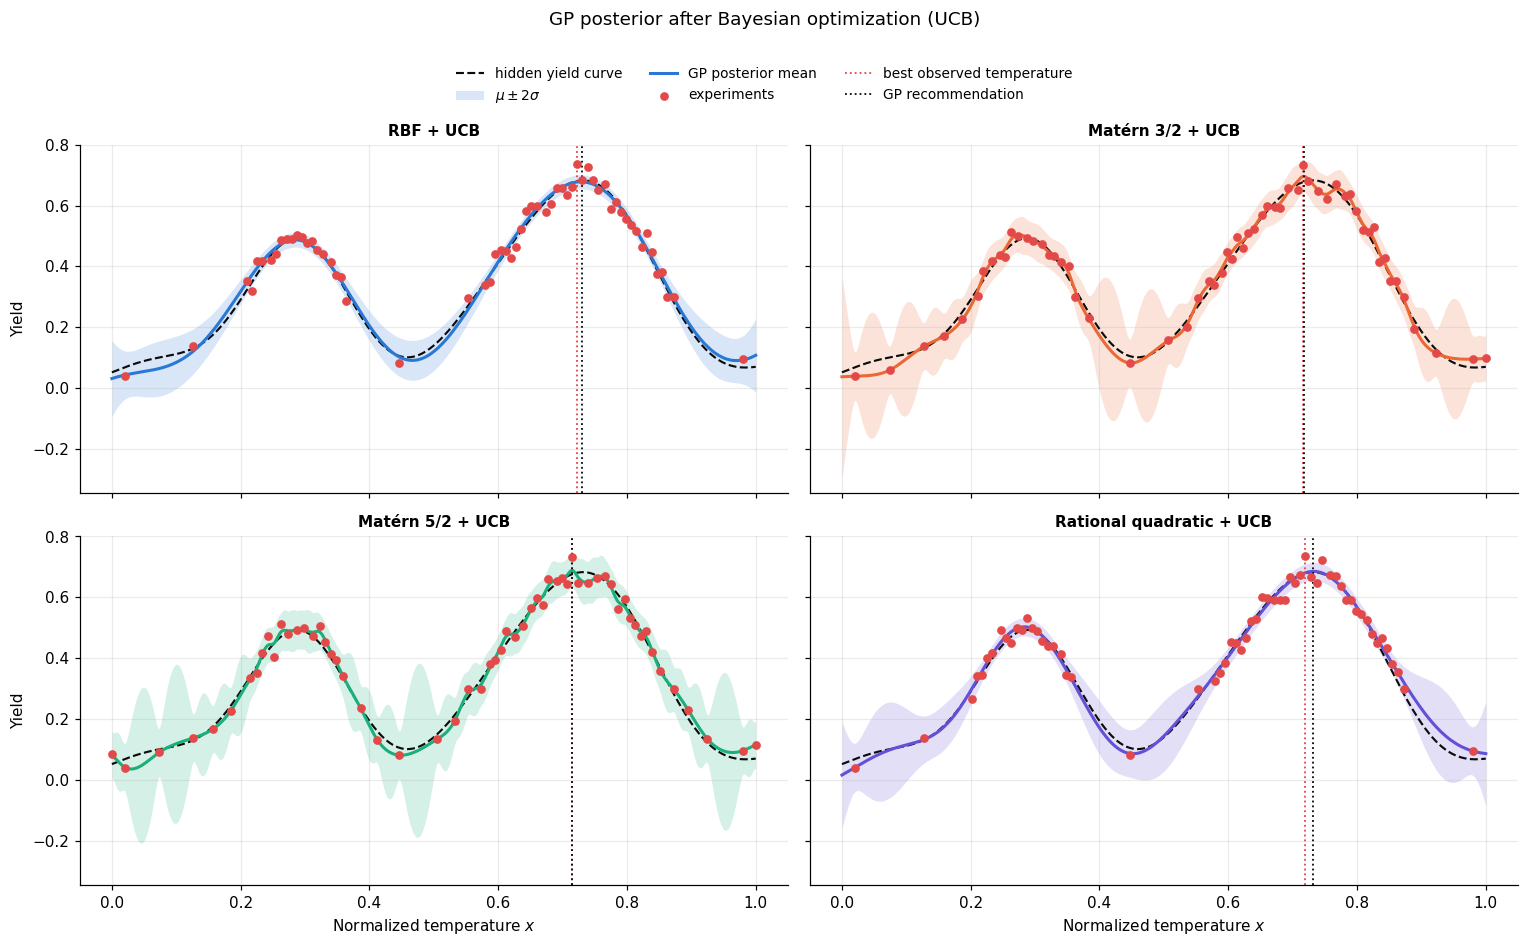

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
axes = axes.flatten()

for ax, kernel_name in zip(axes, kernels):
    res = results[f"{kernel_name}_ucb"]
    gp_vis = ExactGP(lengthscale=0.16, noise_std=0.04, kernel=kernel_name).fit(res["X"], res["y"])
    mu, sd = gp_vis.predict(grid_np)
    mu, sd = mu.cpu().numpy(), sd.cpu().numpy()

    ax.plot(grid_np, true_y, color=COLOR["truth"], ls="--", lw=1.4, label="hidden yield curve")
    ax.fill_between(grid_np, mu - 2 * sd, mu + 2 * sd, color=COLOR[kernel_name], alpha=0.18, lw=0, label="$\\mu \\pm 2\\sigma$")
    ax.plot(grid_np, mu, color=COLOR[kernel_name], lw=2, label="GP posterior mean")
    ax.scatter(res["X"], res["y"], color=COLOR["obs"], s=22, zorder=3, label="experiments")
    ax.axvline(res["best_x"], color=COLOR["obs"], ls=":", lw=1.2, label="best observed temperature")
    ax.axvline(res["rec_x"], color=COLOR["truth"], ls=":", lw=1.2, label="GP recommendation")
    ax.set_title(f"{LABEL[kernel_name]} + UCB", fontsize=10)

for ax in axes[2:]:
    ax.set_xlabel("Normalized temperature $x$")
for ax in axes[::2]:
    ax.set_ylabel("Yield")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=3, fontsize=9)
fig.suptitle("GP posterior after Bayesian optimization (UCB)", y=1.07)
plt.tight_layout()
plt.show()

### 6. Discussion questions

**Q1. Why not optimize the GP posterior mean alone?**

**Hint:** Ask what happens if the first few noisy observations are slightly misleading. Can a mean-only strategy ever correct itself?


**Q2. Why is Bayesian optimization useful here?**
**Hint:** Think about cost per evaluation versus cost of the algorithm


**Q3. Why can the "best observed" answer rank random search above BO?**
**Hint:** If you take the max of many noisy measurements of the same true value, is the max centered on that value?


**Q4. What does the synthetic benchmark not demonstrate?**



---

## Part II — Active learning

### 7. The problem: labels are expensive, unlabeled data is cheap

**The situation.** A public-health office has survey answers from thousands of people. For every person it would like to know one more thing, "does this person have diabetes?", but finding that out costs something: a blood test, a doctor's visit, an expert reading a file. We can afford to find out for a few hundred people, not for everyone. We want to use those few hundred answers to train a classifier that guesses the answer for everybody else, and we want that classifier to be as good as possible.

So the question is not *how to train a classifier* (that part is standard). It is: **which few hundred people should we pay to find out about?**

**Two ways to choose.**
- *Random sampling:* pick people at random. Simple, unbiased, and the baseline everything must beat.
- *Active learning:* train a classifier on the few answers we already have, ask it which people it is **least sure about**, pay for exactly those, retrain, and ask again. The classifier chooses its own training data.

The bet behind active learning: a label the model could already predict with confidence teaches it almost nothing, while a label it was unsure about (or would have got wrong) moves the decision boundary. Spend the budget where the model is unsure.

**Vocabulary.** These words are used throughout the part; if one is unfamiliar, come back to this table.

| Word | Meaning here |
|---|---|
| **pool** | the records whose label we *could* buy: 3,750 survey rows, labels hidden from the learner |
| **labeled set** | the records whose label we have bought so far; it grows every round |
| **seed set** | the first 50 labels, chosen at random, that every strategy starts from |
| **oracle** (annotator) | whoever reveals a label when asked; here it is simply the hidden label column of the data set |
| **query** | asking the oracle for the label of one record; a **batch** is 50 queries at once |
| **round** | train the classifier, score the pool, buy one batch, repeat |
| **budget** | how many labels we can buy in total: 10 rounds of 50, so 500 on top of the seed set |
| **test set** | 1,250 records kept aside, never queried, used only to measure how good the classifier has become |
| **confidence** | the probability the classifier gives its favourite class for a record, $\max_c p(c \mid x)$; between 0.5 and 1 when there are two classes |

The loop from the introduction, with the Part II objects filled in:

```text
   seed set (50 labels)
          │
          ▼
  ┌───────────────────────┐    ┌───────────────────────────┐    ┌──────────────────────────┐
  │ train the classifier  │───▶│ score every unlabeled     │───▶│ choose 50 records:       │
  │ on the labeled set    │    │ record: its confidence    │    │  random,  OR             │
  └───────────────────────┘    └───────────────────────────┘    │  the 50 least confident  │
          ▲                                                     └────────────┬─────────────┘
          │                    ┌───────────────────────────┐                 │
          └────────────────────│ oracle reveals their 50   │◀────────────────┘
     labeled set grows by 50   │ labels (this is what we   │
                               │ pay for)                  │
                               └───────────────────────────┘

  after every "train": grade the classifier on the untouched test set  →  one point of the learning curve
```

#### The idea in one picture, on a toy problem

Before the survey data, a problem small enough to see everything at once: 400 points with two features, two classes that overlap in the middle, and a straight-line classifier (logistic regression). We hide all labels except 6, let each strategy buy 12 more, and watch what happens to the decision boundary. Nothing in this cell is reused later; it is run-only.

In [ ]:
# A toy version of the whole of Part II: two features, two classes, one linear classifier.
# Everything is visible here (we know every label), so we can watch what each strategy buys.
from sklearn.linear_model import LogisticRegression

rng_toy = np.random.default_rng(5)
n_toy, n_seed_toy, n_buy_toy = 400, 6, 12
X_toy = np.vstack([rng_toy.normal([-1.3, -0.5], [1.1, 0.9], size=(n_toy // 2, 2)),
                   rng_toy.normal([ 1.3,  0.5], [1.1, 0.9], size=(n_toy // 2, 2))])
y_toy = np.repeat([0, 1], n_toy // 2)
X_toy_test = np.vstack([rng_toy.normal([-1.3, -0.5], [1.1, 0.9], size=(1000, 2)),
                        rng_toy.normal([ 1.3,  0.5], [1.1, 0.9], size=(1000, 2))])
y_toy_test = np.repeat([0, 1], 1000)

# The seed set: 3 labels of each class, far from the overlap so that the first classifier is a poor guess.
seed_toy = np.concatenate([np.argsort(X_toy[:, 0])[:3], np.argsort(X_toy[:, 0])[-3:]])
unl_toy = np.setdiff1d(np.arange(n_toy), seed_toy)

clf0 = LogisticRegression().fit(X_toy[seed_toy], y_toy[seed_toy])
conf_toy = clf0.predict_proba(X_toy[unl_toy]).max(1)                  # confidence of the first classifier
buy = {"Random sampling": rng_toy.choice(unl_toy, n_buy_toy, replace=False),
       "Uncertainty sampling": unl_toy[np.argsort(conf_toy)[:n_buy_toy]]}   # the least confident records
clf_all = LogisticRegression().fit(X_toy, y_toy)                      # the boundary with every label known

xx, yy = np.meshgrid(np.linspace(-4.5, 4.5, 200), np.linspace(-3.5, 3.5, 200))
grid_toy = np.c_[xx.ravel(), yy.ravel()]

def draw_boundary(ax, clf, **kw):
    ax.contour(xx, yy, clf.predict_proba(grid_toy)[:, 1].reshape(xx.shape), levels=[0.5], **kw)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
ax = axes[0]
cf = ax.contourf(xx, yy, clf0.predict_proba(grid_toy).max(1).reshape(xx.shape), levels=np.linspace(0.5, 1, 11), cmap="Greys_r", alpha=0.55)
ax.scatter(X_toy[unl_toy, 0], X_toy[unl_toy, 1], s=12, color=COLOR["grey"], label="unlabeled (label hidden)")
for c in [0, 1]:
    s = seed_toy[y_toy[seed_toy] == c]
    ax.scatter(X_toy[s, 0], X_toy[s, 1], s=90, color=COLOR[f"class{c}"], edgecolor="black", lw=0.8, zorder=5, label=f"seed label, class {c}")
draw_boundary(ax, clf0, colors=COLOR["ink"], linewidths=2)
ax.set_title(f"Start: {n_seed_toy} labels. Dark band = classifier unsure", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
fig.colorbar(cf, ax=ax, fraction=0.04, pad=0.02, label="classifier confidence  max p(c | x)")

for ax, name in zip(axes[1:], buy):
    chosen = buy[name]
    idx = np.concatenate([seed_toy, chosen])
    clf1 = LogisticRegression().fit(X_toy[idx], y_toy[idx])
    acc0 = clf0.score(X_toy_test, y_toy_test); acc1 = clf1.score(X_toy_test, y_toy_test)
    ax.scatter(X_toy[unl_toy, 0], X_toy[unl_toy, 1], s=12, color=COLOR["grey"])
    ax.scatter(X_toy[seed_toy, 0], X_toy[seed_toy, 1], s=90, facecolor="none", edgecolor="black", lw=0.8, zorder=4, label="seed set")
    for c in [0, 1]:
        s = chosen[y_toy[chosen] == c]
        ax.scatter(X_toy[s, 0], X_toy[s, 1], s=70, marker="*", color=COLOR[f"class{c}"], edgecolor="black", lw=0.5, zorder=5, label=f"bought, revealed class {c}")
    draw_boundary(ax, clf0, colors=COLOR["ink"], linewidths=1.2, linestyles=":")
    draw_boundary(ax, clf1, colors=COLOR[name], linewidths=2.5)
    draw_boundary(ax, clf_all, colors=COLOR["truth"], linewidths=1.2, linestyles="--")
    ax.plot([], [], color=COLOR["ink"], ls=":", label="boundary before buying")
    ax.plot([], [], color=COLOR[name], lw=2.5, label=f"boundary after buying {n_buy_toy}")
    ax.plot([], [], color=COLOR["truth"], ls="--", label=f"boundary with all {n_toy} labels")
    ax.set_title(f"{name} buys {n_buy_toy} labels: test accuracy {acc0:.2f} → {acc1:.2f}", fontsize=10)
    ax.legend(fontsize=7.5, loc="lower left")
for ax in axes:
    ax.set_xlim(-4.5, 4.5); ax.set_ylim(-3.5, 3.5); ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")
plt.tight_layout()
plt.show()
print(f"Accuracy with all {n_toy} labels: {clf_all.score(X_toy_test, y_toy_test):.2f}")

**Reading the three panels.**
- *Left.* With 6 labels the classifier has drawn a line. The grey shading is how sure it is about each point: white far from the line (confident), dark along it (unsure, confidence close to 0.5). That dark band is where the next labels should come from.
- *Middle.* Random sampling buys 12 points scattered over the whole cloud. Most land in white regions, where the classifier already knew the answer, so the new line (green) barely improves on the old one (dotted). It can even get worse, as here.
- *Right.* Uncertainty sampling buys the 12 darkest points, all along the old line. Their revealed labels show exactly where that line was wrong, and the new line (blue) now cuts through the overlap in the right place: its test accuracy equals that of the classifier trained on all 400 labels (dashed).

Same budget, same starting point, different choice of *which* labels: that is the entire content of this part. Everything that follows is the same experiment on a real data set, with a language model producing the features instead of two hand-made ones, and repeated over several random starts so that the comparison can be trusted.

### The real problem: the CDC diabetes survey

**The situation.** A public-health office has survey answers from thousands of people. For every person it would like to know one more thing, "does this person have diabetes?", but finding that out costs something: a blood test, a doctor's visit, an expert reading a file. We can afford to find out about a few hundred people, not for everyone. We want to use those few hundred answers to train a classifier that guesses the answer for everybody else, and we want that classifier to be as good as possible.

**The data.** The CDC Diabetes Health Indicators survey (UCI repository, id 891): 21 survey answers per adult respondent (blood pressure, cholesterol, BMI, smoking, general health, age bracket, income, ...) and a binary target, whether the respondent reports diabetes or prediabetes. We draw a stratified subset of 5,000 records. About 14 % are positive, so the classes are **imbalanced**: a classifier that says "no diabetes" to everyone is right 86 % of the time while being useless. This matters for how we train and for how we score, and section 9 comes back to it.

**The pipeline.** A survey row is 21 numbers, and a classifier could use them directly. Here each row takes a detour through a language model, for two reasons: it is the GPU workload of this exercise, and the same recipe works unchanged for any record that can be written as text (free-text notes, lab reports, product reviews).

```text
survey row ──▶ text  ("HighBP: 1 … Question: does this respondent report diabetes or prediabetes?")
           ──▶ frozen LLM (Qwen2.5-0.5B-Instruct) reads the text ──▶ one 896-number "fingerprint" per record (the embedding)
           ──▶ small linear classifier (the "head"), trained only on the labeled records
           ──▶ confidence on every unlabeled record ──▶ buy 50 labels ──▶ retrain the head ──▶ …
```

The language model is a **fixed feature extractor**: it is never fine-tuned, and the GPU runs it once over the 5,000 records. Only the small head is retrained at every round, which keeps the loop fast (seconds, not minutes).

**The two strategies**, each starting from the same seed set:
- **Random sampling:** choose 50 unlabeled records uniformly at random.
- **Least-confidence (uncertainty) sampling:** choose the 50 unlabeled records whose confidence is smallest, i.e. whose *uncertainty* $u(x) = 1 - \max_c\, p(c \mid x)$ is largest.

The true labels stay hidden from the learner; the oracle reveals them only for queried records. A held-out test set of 1,250 records, never queried, measures the result.

The next cell downloads the data (a few seconds) and prints the first rows.

In [ ]:
%pip install -q transformers accelerate ucimlrepo

import numpy as np, pandas as pd, torch, time
from torch import nn
from transformers import AutoTokenizer, AutoModel
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.decomposition import PCA

# Use a reproducible, stratified subset so the exercise remains practical.
SAMPLE_SIZE = 5000  # try 2000 for a quicker run, or 10000+ with sufficient GPU time

def load_dataset(sample_size=SAMPLE_SIZE, seed=SEED):
    """Load CDC Diabetes Health Indicators from UCI and return a stratified binary subset."""
    dataset = fetch_ucirepo(id=891)
    X = dataset.data.features.copy()
    targets = dataset.data.targets.copy()

    # Prefer the binary target. Some versions expose the three-class Diabetes_012 target.
    target_candidates = [c for c in targets.columns if c.lower() == "diabetes_binary"]
    if target_candidates:
        target_col = target_candidates[0]
        y = targets[target_col].astype(int).to_numpy()
    else:
        multiclass = [c for c in targets.columns if c.lower() == "diabetes_012"]
        if not multiclass:
            raise ValueError(f"Could not find a supported diabetes target. Available targets: {list(targets.columns)}")
        # Keep the task binary: 0 = no diabetes, 1 = prediabetes or diabetes.
        y = (targets[multiclass[0]].astype(int).to_numpy() > 0).astype(int)

    # Remove identifier-like columns if present; they are not predictive features.
    id_cols = [c for c in X.columns if c.lower() in {"id", "patient_id"}]
    X = X.drop(columns=id_cols, errors="ignore")
    X = X.apply(pd.to_numeric, errors="coerce")
    if X.isna().any().any():
        # The source is generally complete; if a version contains missing values,
        # use per-column medians rather than dropping a large number of records.
        X = X.fillna(X.median(numeric_only=True)).fillna(0)

    if sample_size is not None and sample_size < len(X):
        all_idx = np.arange(len(X))
        selected_idx, _ = train_test_split(
            all_idx, train_size=sample_size, stratify=y, random_state=seed
        )
        X = X.iloc[selected_idx].reset_index(drop=True)
        y = y[selected_idx]
    else:
        X = X.reset_index(drop=True)

    cfg = dict(
        name="CDC Diabetes Health Indicators",
        prefix="Public-health survey record for an adult respondent.",
        question="Question: does this respondent report diabetes or prediabetes?",
        units={},
        missing_if_zero=set()
    )
    return X, y, cfg

X_df, y_all, DATA_CFG = load_dataset()
print(f"Dataset: {DATA_CFG['name']}  |  sampled records: {len(X_df):,}  |  features: {X_df.shape[1]}  "
      f"|  positive rate: {y_all.mean():.3f}")
print("Class counts:", dict(zip(*np.unique(y_all, return_counts=True))))
X_df.head()

#### A glimpse of the data

Left: the class balance. Right: three of the 21 answers, split by class. Respondents who report diabetes tend to have a higher BMI, rate their general health worse (1 = excellent, 5 = poor) and sit in the older age brackets. But look at how much the two colours overlap: no single answer separates the classes. The classifier needs all 21 answers together, and even then its accuracy will stay well below 100 %, because the survey simply does not contain enough information to tell every case apart. Keep that in mind when the learning curves later level off around 75 %.

In [ ]:
glimpse = {"BMI": np.arange(10, 70, 2), "GenHlth": np.arange(0.5, 6.5, 1), "Age": np.arange(0.5, 14.5, 1)}
titles = {"BMI": "Body-mass index", "GenHlth": "General health (1 = excellent, 5 = poor)", "Age": "Age bracket (1 = 18–24, …, 13 = 80+)"}

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
counts = np.bincount(y_all, minlength=2)
axes[0].bar(["no diabetes\n(class 0)", "diabetes or\nprediabetes (class 1)"], counts,
            color=[COLOR["class0"], COLOR["class1"]], width=0.6)
for i, c in enumerate(counts):
    axes[0].text(i, c, f"{c:,}  ({100 * c / counts.sum():.0f} %)", ha="center", va="bottom", fontsize=9)
axes[0].set_title("Class balance", fontsize=10)
axes[0].set_ylabel("Records")
axes[0].set_ylim(0, counts.max() * 1.15)

for ax, col in zip(axes[1:], glimpse):
    for cls in [0, 1]:
        ax.hist(X_df.loc[y_all == cls, col], bins=glimpse[col], density=True, alpha=0.55,
                color=COLOR[f"class{cls}"], label=f"class {cls}")
    ax.set_title(titles[col], fontsize=10)
    ax.set_ylabel("Density within the class")
axes[1].legend()
plt.tight_layout()
plt.show()

#### From a row of numbers to a short text, and the pool / test split

The next cell does two small things.

1. **Serializes** each row as text: one line per answer, `name: value`, with a sentence before and a question after. A language model only reads text, so this is how a survey row enters it. The printed example shows one record in that form.
2. **Splits** the 5,000 records once and for all:

```text
   5,000 records
   ├── pool  3,750   labels hidden; this is what the strategies buy from (the seed set is drawn from here)
   └── test  1,250   labels used only to grade the classifier; never queried, never trained on
```

The split is *stratified*: both parts keep the same 14 % share of positives.

In [ ]:
def row_to_text(row, cfg=DATA_CFG):
    """Serialize one survey row as text for the language-model embedding step."""
    lines = []
    for col, val in row.items():
        if pd.isna(val):
            value_text = "unknown"
        else:
            # These variables are mostly small integer-coded survey responses.
            value_text = f"{val:g}" if isinstance(val, (int, float, np.integer, np.floating)) else str(val)
        lines.append(f"{col}: {value_text}")
    return cfg["prefix"] + "\n" + "\n".join(lines) + "\n" + cfg["question"]

texts_all = [row_to_text(r) for _, r in X_df.iterrows()]
print("Example serialized record:\n", texts_all[0])

# Held-out test set: never used for training or for choosing queries.
idx_pool, idx_test = train_test_split(
    np.arange(len(y_all)), test_size=0.25, stratify=y_all, random_state=SEED
)
y_pool_np, y_test_np = y_all[idx_pool], y_all[idx_test]
print(f"\nPool: {len(idx_pool):,}  |  Test: {len(idx_test):,}")

### 8. Embeddings from a frozen language model

**What an embedding is.** When a language model reads a text, every token comes out as a vector of numbers (896 of them for this model) that encodes what the model "understood" about that token in its context. Average those vectors over all the tokens of a record and you get one 896-number summary of the whole record: its **embedding**. Records the model finds similar get similar embeddings. That is all a classifier needs: a fixed-length list of numbers per record, with the structure of the data baked in.

In formulas: the last hidden states $h_1, \dots, h_T$ are averaged over the non-padding tokens,

$$ e = \frac{\sum_t m_t\, h_t}{\sum_t m_t}, \qquad m_t \in \{0, 1\} \text{ the attention mask,} $$

where $m_t$ is 1 for a real token and 0 for the padding added so that all records in a batch have the same length. The `🎯TODO` in the cell is exactly this line.

**Practicalities.** The model runs in `bfloat16` on the GPU, in batches of 32, under `torch.no_grad()` (no gradients: nothing is trained). The embeddings are then **standardized** (each of the 896 dimensions is shifted and scaled to mean 0 and standard deviation 1) using the mean and standard deviation of the *pool* only, so that the test set never influences the features. The vector $e$ is the only thing the classifier will ever see; the LLM is not touched again after this cell.

In [ ]:
LLM_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
POOLING = "mean"  # "mean" or "last"

# Batch size 32 is a conservative default for GPU memory; lower it if needed.
EMBED_BATCH_SIZE = 32
MAX_LENGTH = 192

tokenizer = AutoTokenizer.from_pretrained(LLM_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"
llm = AutoModel.from_pretrained(
    LLM_NAME, dtype=torch.bfloat16 if DEVICE.type == "cuda" else torch.float32
).to(DEVICE).eval()

@torch.no_grad()
def embed_texts(texts, batch_size=EMBED_BATCH_SIZE, max_length=MAX_LENGTH, pooling=POOLING):
    out = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i+batch_size], padding=True, truncation=True,
                        max_length=max_length, return_tensors="pt").to(DEVICE)
        h = llm(**enc).last_hidden_state.float()
        mask = enc["attention_mask"].unsqueeze(-1).float()
        if pooling == "mean":
            # 🎯TODO: average hidden states over non-padding tokens
            e = ...
        else:
            last = ...
            e = h[torch.arange(h.size(0), device=DEVICE), last]
        out.append(e.cpu())  # keep the complete embedding matrix in CPU memory
        if DEVICE.type == "cuda" and (i // batch_size) % 25 == 0:
            torch.cuda.empty_cache()
    return torch.cat(out)

t0 = time.time()
E_all = embed_texts(texts_all)
print(f"Embedded {len(texts_all):,} records -> {tuple(E_all.shape)} in {time.time()-t0:.1f}s on {DEVICE}")

# Standardize using the pool only. Embeddings are kept on CPU until needed by the classifier.
E_pool, E_test = E_all[idx_pool], E_all[idx_test]
mu_e, sd_e = E_pool.mean(0, keepdim=True), E_pool.std(0, keepdim=True).clamp_min(1e-6)
E_pool, E_test = (E_pool - mu_e) / sd_e, (E_test - mu_e) / sd_e
E_pool, E_test = E_pool.to(DEVICE), E_test.to(DEVICE)

y_pool = torch.tensor(y_pool_np, dtype=torch.long, device=DEVICE)
y_test = torch.tensor(y_test_np, dtype=torch.long, device=DEVICE)

#### What the embeddings look like

Left: six records, three per class, as rows of numbers (only the first 60 of the 896 dimensions are shown). To a human the rows look like noise; to a linear classifier they are coordinates in a space where "diabetes" and "no diabetes" lean in different directions. Right: all 3,750 pool embeddings squashed to two dimensions by PCA and coloured by their **true** label. The learner is never allowed to see this picture (it would need every label), but it tells us what the learner is up against: the positives are concentrated on the right, yet mixed in with negatives everywhere. There is structure to learn, and no clean separation.

In [ ]:
# Two views of the embeddings. Left: the first 60 of the 896 numbers for six records, three of each class.
# Right: all 3,750 pool embeddings squashed to two dimensions, coloured by the TRUE label (which the learner never sees).
show = np.concatenate([np.where(y_pool_np == 0)[0][:3], np.where(y_pool_np == 1)[0][:3]])
Z_hidden = PCA(n_components=2, random_state=SEED).fit_transform(E_pool.cpu().numpy())

fig, axes = plt.subplots(1, 2, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
im = axes[0].imshow(E_pool[show, :60].cpu().numpy(), cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
axes[0].set_yticks(range(len(show)))
axes[0].set_yticklabels([f"pool record {i}  (class {y_pool_np[i]})" for i in show], fontsize=9)
axes[0].set_xlabel("embedding dimension (first 60 of 896)")
axes[0].set_title("One record = one row of 896 numbers (standardized)", fontsize=10)
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], fraction=0.03, pad=0.02)

for cls, marker, z in [(0, "o", 1), (1, "^", 2)]:
    m = y_pool_np == cls
    axes[1].scatter(Z_hidden[m, 0], Z_hidden[m, 1], s=6, marker=marker, color=COLOR[f"class{cls}"], alpha=0.5, zorder=z,
                    label=f"class {cls} ({m.sum():,} records)")
axes[1].set_xlabel("principal component 1"); axes[1].set_ylabel("principal component 2")
axes[1].set_title("The pool in 2-D, coloured by the hidden true label", fontsize=10)
axes[1].legend(fontsize=8, markerscale=2.5)
plt.tight_layout()
plt.show()

### 9. The classifier head, and which accuracy to read

**The head.** A dropout layer and a single linear layer from 896 numbers to 2 scores, followed by a softmax that turns the scores into probabilities. It is trained with Adam on the whole labeled set at once (at most 550 records, so this takes a fraction of a second). Because only 14 % of the records are positive, the cross-entropy is **class-weighted**: class $c$ gets the weight $w_c = N / (2 N_c)$, so a mistake on a positive costs about six times a mistake on a negative, and both classes contribute equally to the loss.

**Which accuracy to read.** Imagine 100 respondents, 86 without and 14 with diabetes, and a "classifier" that says *no diabetes* to all of them.

| | correct on class 0 | correct on class 1 | accuracy | balanced accuracy |
|---|---|---|---|---|
| always "no diabetes" | 86 / 86 | 0 / 14 | **86 %** | (100 % + 0 %) / 2 = **50 %** |
| a head that finds 3 in 4 of each class | 65 / 86 | 11 / 14 | 76 % | (75 % + 75 %) / 2 = **75 %** |

**Accuracy** (share of all records classified correctly) rewards ignoring the minority: the useless rule scores higher. **Balanced accuracy** (the average of the per-class recalls, "what share of each class did you find?") gives the useless rule 50 % whatever the imbalance, and only rises when the classifier finds *both* classes. The weighted head deliberately trades accuracy for balanced accuracy: it predicts "diabetes" often enough to find most positives, at the cost of false alarms. So in everything below, **balanced accuracy is the number to read**, and an accuracy below 86 % is not a bug.

The next cell trains the head once on all 3,750 pool labels. That run is the **ceiling** of this pipeline: no choice of 550 labels can beat a head that saw every label. It also draws two confusion matrices, explained right after.

In [ ]:
def train_head(X, y, epochs=300, lr=3e-3, weight_decay=1e-2, dropout=0.2, seed=0):
    torch.manual_seed(seed)
    head = nn.Sequential(nn.Dropout(dropout), nn.Linear(X.shape[1], 2)).to(DEVICE)
    counts = torch.bincount(y, minlength=2).float().clamp_min(1.0)
    class_w = counts.sum() / (2 * counts)                     # balance the two classes
    # 🎯TODO: define the Adam optimizer and the class-weighted cross-entropy loss
    opt = ...
    loss_fn = ...
    head.train()
    for _ in range(epochs):
        opt.zero_grad(set_to_none=True)
        loss = loss_fn(head(X), y)
        loss.backward()
        opt.step()
    return head

@torch.no_grad()
def predict_proba(head, X):
    head.eval()
    #🎯TODO Return prediction probabilities
    return ...

@torch.no_grad()
def evaluate(head, X, y):
    pred = predict_proba(head, X).argmax(1).cpu().numpy()
    yt = y.cpu().numpy()
    #🎯TODO Return the accuracy and balanced score
    return ...

# Reference: head trained on the fully labeled pool (an upper bound for this pipeline)
full_head = train_head(E_pool, y_pool)
FULL_ACC, FULL_BACC = evaluate(full_head, E_test, y_test)
print(f"Fully labeled pool ({len(y_pool)} labels): accuracy={FULL_ACC:.3f}, balanced acc={FULL_BACC:.3f}")
print(f"Majority-class baseline accuracy: {max(y_test_np.mean(), 1 - y_test_np.mean()):.3f}")
print(f"Majority-class baseline balanced accuracy: 0.500")

from sklearn.metrics import confusion_matrix

def plot_confusion(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.sum())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({100 * cm[i, j] / cm[i].sum():.0f} % of class {i})",
                    ha="center", va="center", fontsize=9, color="white" if cm[i, j] > cm.sum() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["predicted 0", "predicted 1"]); ax.set_yticklabels(["true 0", "true 1"])
    ax.set_title(title, fontsize=10)
    ax.grid(False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
full_pred = predict_proba(full_head, E_test).argmax(1).cpu().numpy()
plot_confusion(axes[0], y_test_np, full_pred, f"Head on all {len(y_pool)} labels: accuracy {FULL_ACC:.3f}, balanced {FULL_BACC:.3f}")
plot_confusion(axes[1], y_test_np, np.zeros_like(y_test_np),
               f"Always 'no diabetes': accuracy {1 - y_test_np.mean():.3f}, balanced 0.500")
plt.tight_layout()
plt.show()

### 10. The active-learning loop

This is where the pieces come together. We compare two strategies that start with the same 50 labeled examples and have the same budget for acquiring additional labels. They differ only in how they select the next batch.

**At each round, the process is:**

1. **Train:** fit the classifier head using all labels acquired so far.
2. **Predict:** use the head to estimate class probabilities for every record still in the unlabeled pool.
3. **Select:** choose a batch of 50 records to label.
   - **Random sampling** selects 50 records uniformly at random.
   - **Least-confidence sampling** selects the 50 records for which the model's highest predicted class probability is smallest.
4. **Query the oracle:** reveal the true labels of the selected records and add them to the labeled set.
5. **Evaluate:** measure performance on the fixed test set.
6. **Repeat:** retrain the head with the enlarged labeled set and select another batch.

After 10 rounds, each strategy has acquired 500 additional labels, on top of the original seed set of 50.

#### What does “least confident” mean?

For a record \(x\), the classifier estimates a probability for each class. Its confidence is the largest of those probabilities:

$$
\operatorname{confidence}(x) = \max_c p(c \mid x)
$$

For example, if the model predicts probabilities of 0.52 and 0.48, its confidence is 0.52: it is almost undecided. If it predicts 0.97 and 0.03, its confidence is 0.97: it strongly favours one class.

Least-confidence sampling chooses records with the smallest maximum probability. It does not need to know the true labels to do this; it uses only the model's predictions.

#### Why retrain after each batch?

The newly acquired labels provide additional information. After retraining, the model's predictions and confidence scores can change, so the next batch should be selected using the updated model. Active learning is therefore a repeated feedback loop, not a one-time selection of the 500 most uncertain records.

**A note about the oracle:** in this notebook, the dataset already contains the true labels, so the code can reveal a selected record's label immediately. This simulates a real annotation process, in which a human expert or another labeling procedure would provide the answer. The selection strategy must not use hidden pool labels before choosing which records to query.

In [ ]:
INITIAL, QUERY, ROUNDS, N_SEEDS = 50, 50, 10, 5

def make_initial_set(seed, initial_size=INITIAL):
    """Create a shared initial labeled set containing both classes."""
    rng = np.random.default_rng(seed)
    n = len(y_pool_np)
    while True:
        init = rng.choice(n, size=initial_size, replace=False)
        if len(np.unique(y_pool_np[init])) == 2:
            return init

def run_active_learning_llm(strategy, initial_indices, rounds=ROUNDS, query_size=QUERY, seed=0):
    rng = np.random.default_rng(seed + 10_000)
    n = len(y_pool_np)
    labeled = list(np.asarray(initial_indices, dtype=int))
    # 🎯TODO:Update the pool
    unlabeled = ...
    history, batches, pools, confidences = [], [], [], []
    for r in range(rounds + 1):
        # 🎯TODO: train a fresh classifier head on the currently labeled records only.
        #   1. Turn the list `labeled` into a LongTensor of indices on DEVICE.
        #   2. Select those rows from E_pool (embeddings) and y_pool (labels).
        #   3. Call train_head(...) with seed=seed + r.
        ids = ...
        head = ...
        acc, bacc = evaluate(head, E_test, y_test)
        history.append({"n_labeled": len(labeled), "accuracy": acc, "balanced_accuracy": bacc})
        # The head's confidence on the unlabeled pool (kept for both strategies, for the diagnostics below)
        probs = predict_proba(head, E_pool[torch.as_tensor(unlabeled, dtype=torch.long, device=DEVICE)])
        # 🎯TODO: Define the confidence
        confidence = ...
        pools.append(unlabeled.copy())
        confidences.append(confidence)
        if r == rounds:
            break
        if strategy == "random":
            chosen = rng.choice(unlabeled, size=min(query_size, len(unlabeled)), replace=False)
        elif strategy == "uncertainty":
            # 🎯TODO: least-confidence sampling: query the records whose largest class probability is smallest
            uncertainty = ...
            chosen = unlabeled[np.argsort(uncertainty)[-min(query_size, len(unlabeled)):]]
        else:
            raise ValueError("strategy must be 'random' or 'uncertainty'")
        batches.append(np.asarray(chosen))
        labeled.extend(chosen.tolist())
        unlabeled = np.setdiff1d(unlabeled, chosen)
    return {"history": pd.DataFrame(history), "labeled": np.array(labeled), "initial": np.asarray(initial_indices),
            "batches": batches, "pools": pools, "confidences": confidences}

# Fair comparison: each strategy starts from exactly the same seed set for a given run.
t0 = time.time()
al_llm = {"Random sampling": [], "Uncertainty sampling": []}
for s in range(N_SEEDS):
    initial = make_initial_set(s)
    al_llm["Random sampling"].append(run_active_learning_llm("random", initial, seed=s))
    al_llm["Uncertainty sampling"].append(run_active_learning_llm("uncertainty", initial, seed=s))
print(f"Done in {time.time()-t0:.1f}s\n")

for name, runs in al_llm.items():
    final = pd.DataFrame([r["history"].iloc[-1] for r in runs])
    print(f"{name:>22s}: labels={int(final.n_labeled.iloc[0])}, "
          f"accuracy={final.accuracy.mean():.3f} ± {final.accuracy.std():.3f}, "
          f"balanced acc={final.balanced_accuracy.mean():.3f} ± {final.balanced_accuracy.std():.3f}")

#### The loop, round by round

One run (uncertainty sampling, random seed 0) watched at five of its rounds. Each panel is the histogram of the head's confidence over the records still unlabeled at that moment, and in blue the 50 records bought in that round: always the leftmost sliver, the records on which the head is closest to a coin flip. After the purchase the head is retrained and re-scores everything, so by the next panel the histogram has changed: with more labels the tall spike at confidence 1.0 melts away, as the head becomes less over-confident. The uncertain tail never empties, because every retrained head is unsure about something new.

In [ ]:
# Uncertainty sampling, random seed 0, watched round by round: the head's confidence on what is still unlabeled,
# and in blue the 50 records it buys next. After each purchase the head is retrained and re-scores everything.
run_show = al_llm["Uncertainty sampling"][0]
show_rounds = [0, 1, 3, 6, 9]
bins = np.linspace(0.5, 1.0, 26)

fig, axes = plt.subplots(1, len(show_rounds), figsize=(17, 3.8), sharey=True)
for ax, r in zip(axes, show_rounds):
    conf, pool, batch = run_show["confidences"][r], run_show["pools"][r], run_show["batches"][r]
    bought = conf[np.isin(pool, batch)]
    ax.hist(conf, bins=bins, color=COLOR["grey"], alpha=0.5, label="still unlabeled")
    ax.hist(bought, bins=bins, color=COLOR["Uncertainty sampling"], label="the 50 bought this round")
    ax.axvline(bought.max(), color=COLOR["Uncertainty sampling"], ls="--", lw=1)
    ax.text(bought.max() + 0.015, 700, f"cut-off\n{bought.max():.2f}", fontsize=8, color=COLOR["Uncertainty sampling"])
    ax.set_title(f"Round {r}\n{INITIAL + r * QUERY} labels known, {len(pool):,} unlabeled", fontsize=9.5)
    ax.set_xlabel("head's confidence on the record")
axes[0].set_ylabel("Records")
axes[0].legend(fontsize=8, loc="upper center")
plt.tight_layout()
plt.show()

#### Learning curves

**How to read a learning curve.** The horizontal axis is money spent (labels bought), the vertical axis is what we got for it (quality on the untouched test set). A strategy whose curve is higher reaches the same quality with fewer labels. Each curve is the mean over the 5 random seeds and the shaded band is one standard deviation across them: where the bands overlap, the difference between the strategies is within run-to-run noise.

Two reference lines: the dotted grey line is the head trained on all 3,750 pool labels, the **ceiling** of this pipeline; the dashed black line is the "always no diabetes" rule. On the left (accuracy) that useless rule sits *above* everything, which is the imbalance trap of section 9; on the right (balanced accuracy) it sits at 0.5, below everything, and the picture makes sense. Read the right panel.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, metric, full in zip(axes, ["accuracy", "balanced_accuracy"], [FULL_ACC, FULL_BACC]):
    for name, runs in al_llm.items():
        M = np.stack([r["history"][metric].to_numpy() for r in runs])
        xs = runs[0]["history"]["n_labeled"].to_numpy()
        ax.plot(xs, M.mean(0), marker="o", ms=4, lw=2, color=COLOR[name], label=name)
        ax.fill_between(xs, M.mean(0) - M.std(0), M.mean(0) + M.std(0), color=COLOR[name], alpha=0.15, lw=0)
        ax.text(xs[-1] + 8, M.mean(0)[-1], f"{M.mean(0)[-1]:.3f}", va="center", fontsize=9, color=COLOR[name])
    ax.axhline(full, color=COLOR["grey"], ls=":", lw=1.5, label=f"all {len(y_pool)} pool labels ({full:.3f})")
    if metric == "accuracy":
        ax.axhline(1 - y_test_np.mean(), color=COLOR["truth"], ls="--", lw=1, label=f"always 'no diabetes' ({1 - y_test_np.mean():.3f})")
    else:
        ax.axhline(0.5, color=COLOR["truth"], ls="--", lw=1, label="always 'no diabetes' (0.500)")
    ax.set_xlabel("Number of labeled training examples")
    ax.set_ylabel(metric.replace("_", " "))
    ax.set_title(f"{metric.replace('_', ' ').capitalize()} on the held-out test set ({N_SEEDS} seeds)", fontsize=10)
    ax.set_xlim(0, 620)
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

#### The same curves read as a price list

A learning curve can also be read sideways: pick a quality level and ask how many labels each strategy needed to reach it (the first point of the mean curve at or above the target). This is the number a practitioner cares about, because it turns the gap between the two curves into a labeling bill.

In [ ]:
# The learning curves read as a price list: how many labels did each strategy need to reach a given balanced accuracy?
from matplotlib.patches import Patch

targets = [0.64, 0.66, 0.68, 0.70]
xs_al = al_llm["Random sampling"][0]["history"]["n_labeled"].to_numpy()
mean_bacc = {name: np.stack([r["history"]["balanced_accuracy"].to_numpy() for r in runs]).mean(0) for name, runs in al_llm.items()}

def labels_needed(curve, target):
    """First number of labels at which the mean curve reaches the target, or None if it never does."""
    hit = np.where(curve >= target)[0]
    return int(xs_al[hit[0]]) if len(hit) else None

def as_text(need):
    return f"{need} labels" if need is not None else f"not reached with {xs_al[-1]}"

price = pd.DataFrame({name: [as_text(labels_needed(c, t)) for t in targets] for name, c in mean_bacc.items()},
                     index=pd.Index([f"{t:.2f}" for t in targets], name="target balanced accuracy"))
display(price)

fig, ax = plt.subplots(figsize=(9, 3.6))
h = 0.36
for k, (name, c) in enumerate(mean_bacc.items()):
    for y0, t in zip(np.arange(len(targets)) + (k - 0.5) * h, targets):
        need = labels_needed(c, t)
        if need is None:
            ax.barh(y0, xs_al[-1], height=h, color=COLOR[name], alpha=0.25, hatch="///", edgecolor=COLOR[name])
            ax.text(xs_al[-1] + 8, y0, f"not reached with {xs_al[-1]}", va="center", fontsize=8, color=COLOR[name])
        else:
            ax.barh(y0, need, height=h, color=COLOR[name])
            ax.text(need + 8, y0, f"{need}", va="center", fontsize=8, color=COLOR[name])
ax.set_yticks(range(len(targets))); ax.set_yticklabels([f"{t:.2f}" for t in targets])
ax.set_ylabel("Target balanced accuracy"); ax.set_xlabel("Labels needed (first point of the mean curve at or above the target)")
ax.set_xlim(0, xs_al[-1] + 130)
ax.set_title("Labels needed to reach a target: the price of each strategy", fontsize=10)
ax.legend(handles=[Patch(color=COLOR[n], label=n) for n in mean_bacc], fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

#### Why uncertainty sampling helps here

Left: the head's confidence on the 3,700 unlabeled records after the seed set only (round 0, random seed 0). Most of the pool already sits far to the right, confidence above 0.9: the head is sure, and a label there would mostly confirm what it predicts anyway. Uncertainty sampling buys the 50 records in the leftmost sliver, the ones the head cannot place; random sampling buys 50 records spread over the whole histogram, which land mostly in the confident region.

Right: the share of positives in each batch of 50, averaged over the seeds. The pool is 14 % positive, and random batches are too. Near the decision boundary the two classes are mixed, so uncertainty sampling buys more minority-class labels than the pool rate. Minority labels are precisely what a classifier on an imbalanced data set is short of, and that is where a good part of the balanced-accuracy gain comes from.

In [ ]:
run_u = al_llm["Uncertainty sampling"][0]
run_r = al_llm["Random sampling"][0]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

# (a) confidence over the unlabeled pool at round 0, and the records each strategy bought
conf0, pool0 = run_u["confidences"][0], run_u["pools"][0]
bins = np.linspace(0.5, 1.0, 41)
axes[0].hist(conf0, bins=bins, color=COLOR["grey"], alpha=0.5, label="unlabeled pool (3,700 records)")
for name, run in [("Uncertainty sampling", run_u), ("Random sampling", run_r)]:
    chosen = run["batches"][0]
    axes[0].hist(conf0[np.isin(pool0, chosen)], bins=bins, color=COLOR[name], alpha=0.85, label=f"50 bought by {name.lower()}")
axes[0].set_xlabel("Head's confidence  $\\max_c\\, p(c \\mid x)$  after the seed set")
axes[0].set_ylabel("Records")
axes[0].set_title("Which records each strategy buys (round 0, seed 0)", fontsize=10)
axes[0].legend(fontsize=8)

# (b) positive-class share of each batch, mean over seeds
for name, runs in al_llm.items():
    share = np.array([[y_pool_np[b].mean() for b in r["batches"]] for r in runs])
    rounds_x = np.arange(1, share.shape[1] + 1)
    axes[1].plot(rounds_x, share.mean(0), marker="o", ms=4, lw=2, color=COLOR[name], label=name)
    axes[1].fill_between(rounds_x, share.mean(0) - share.std(0), share.mean(0) + share.std(0), color=COLOR[name], alpha=0.15, lw=0)
axes[1].axhline(y_pool_np.mean(), color=COLOR["truth"], ls="--", lw=1, label=f"pool rate ({y_pool_np.mean():.2f})")
axes[1].set_xlabel("Query round")
axes[1].set_ylabel("Share of positives in the batch of 50")
axes[1].set_title(f"Class balance of the bought labels ({N_SEEDS} seeds)", fontsize=10)
axes[1].set_ylim(0, 0.8)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

#### The bought labels in embedding space

The pool projected on its first two principal components (the same projection as the hidden-label picture of section 8), one panel per strategy, for random seed 0. Circled points are the shared seed set; blue dots and orange triangles are the 500 bought labels, coloured by what the oracle revealed. Random sampling buys labels everywhere, in proportion to the pool, so many purchases land in the left cluster, which is almost all class 0. Uncertainty sampling buys them where the two classes overlap, mostly in the right-hand clusters, and collects far more orange triangles.

That focus is also its failure mode: nothing stops it from buying fifty near-duplicates from the same corner, or from never visiting a region the head is *confidently wrong* about, since confident records are never queried. Batch methods add a diversity term for the first problem; the second is why random sampling remains a baseline worth running.

**What the projection can and cannot tell you.** PCA compresses 896 dimensions to two, so points that look close on this plot are not necessarily close in the full embedding space. The plot is useful for seeing broad selection patterns, not for proving that every selected record is informative. The failure modes shown here motivate two common improvements: add a diversity criterion so a batch covers different regions, and retain some exploration (for example, a random component) so confidently misclassified regions are not ignored forever.

In [ ]:
Z = PCA(n_components=2, random_state=SEED).fit_transform(E_pool.cpu().numpy())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), sharex=True, sharey=True)
for ax, (name, runs) in zip(axes, al_llm.items()):
    r = runs[0]
    queried = np.setdiff1d(r["labeled"], r["initial"])
    ax.scatter(Z[:, 0], Z[:, 1], s=4, color=COLOR["grey"], alpha=0.25, label="unlabeled pool")
    ax.scatter(Z[r["initial"], 0], Z[r["initial"], 1], s=40, facecolor="none", edgecolor=COLOR["truth"], lw=0.8, label="seed set (shared)")
    for cls, marker in [(0, "o"), (1, "^")]:
        q = queried[y_pool_np[queried] == cls]
        ax.scatter(Z[q, 0], Z[q, 1], s=22, marker=marker, color=COLOR[f"class{cls}"], alpha=0.85, label=f"bought, class {cls}")
    ax.set_title(f"{name}: the 500 labels bought (seed 0)", fontsize=10)
    ax.set_xlabel("PC 1")
axes[0].set_ylabel("PC 2")
axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

### 11. Discussion questions

**Q1. Why might uncertainty sampling outperform random sampling?**
Hint: Picture the pool as a cloud of points with a decision line through it. Which points would change the line most if you knew their labels, the ones far from it or the ones near it?

**Q2. Is uncertainty sampling guaranteed to win?**
Hint: Uncertainty is computed by the model. What if the model is wrong in a way it cannot see?

**Q3. Why is the accuracy below the majority-class baseline, and is that a problem?**
Hint: The head is trained with class-balanced weights. What does that do to the cost of missing a positive versus raising a false alarm, and which way does it move the decision threshold?

**Q4. How is active learning different from semi-supervised learning?**
Hint: Look at what each one does with the unlabeled pool


**Q5. How are BO and AL related?**


**Q6. What would you change for a real expensive simulator or a large data set?**
Hint: Each item in the answer fixes something the notebook quietly assumed.

---

## Bonus — two knobs: temperature *and* time

In one dimension, 60 experiments saturate the interval and random search looks fine. Real reactions have several knobs. Here the chemist controls both the **temperature** $T \in [40, 120]\,^\circ\mathrm{C}$ and the **reaction time** $t \in [10, 180]$ min, normalized to $x_1 = (T-40)/80$ and $x_2 = (t-10)/170$. The synthetic yield surface has a hot, short-time regime that holds the optimum (hotter reactions need shorter times, so the ridge is tilted), a mild, long-time regime that is a local optimum, and small ripples.

The GP code is unchanged: `ExactGP` and the kernels already take inputs of any dimension. Only the candidate grid ($60 \times 60 = 3{,}600$ temperature-time combinations), the initial design (a $3 \times 4$ grid of 12 experiments) and the oracle change. Scoring 3,600 candidates per step is where the GPU earns its keep.

In [ ]:
def objective_2d(X):
    """Synthetic yield as a function of normalized temperature x1 and normalized time x2. X: [n, 2]."""
    X = np.asarray(X, dtype=float).reshape(-1, 2)
    x1, x2 = X[:, 0], X[:, 1]
    u = (x1 - 0.72) / 0.15
    v = (x2 - 0.40 + 0.6 * (x1 - 0.72)) / 0.18          # hotter -> shorter: a tilted ridge
    hot = 0.65 * np.exp(-(u**2 + v**2))
    mild = 0.42 * np.exp(-(((x1 - 0.28) / 0.12)**2 + ((x2 - 0.75) / 0.20)**2))
    ripple = 0.03 * np.sin(8 * np.pi * x1) * np.cos(6 * np.pi * x2)
    return 0.05 + hot + mild + ripple
# 🎯TODO: Explore the objective function.
# Plot the true yield surface as a contour plot.
# Identify the two high-yield regions and explain why the
# global optimum is not necessarily at the center of the domain.
g = ...
G1, G2 = ...
candidate_grid_2d = np.c_[G1.ravel(), G2.ravel()]           # 3,600 temperature-time combinations
true_2d = objective_2d(candidate_grid_2d)
f_max_2d = float(true_2d.max())
x_star_2d = candidate_grid_2d[int(np.argmax(true_2d))]
print(f"True optimum on the grid: {to_celsius(x_star_2d[0]):.1f} °C, {10 + 170 * x_star_2d[1]:.0f} min, yield {f_max_2d:.4f}")

def run_bo_2d(method="ei", n_steps=50, seed=0, kappa=2.0, kernel="rbf", lengthscale=0.16, noise_std=0.04):
    rng = np.random.default_rng(seed)
    # 🎯TODO: build a 3 x 4 grid of initial experiments over [0.1, 0.9]^2
    # (3 values of temperature x1, 4 values of time x2) as an array of shape [12, 2].
    # Column 0 must be temperature and column 1 time.
    a, b = ...
    X = ...
    # 🎯TODO: simulate the 12 initial experiments. Each measurement is the true yield
    # plus Gaussian noise (std 0.025). Use the seeded `rng`, not np.random.
    y = ...
    hist_obs, hist_rec = [], []

    def fit_and_predict(X, y):
        gp = ExactGP(lengthscale=lengthscale, noise_std=noise_std, kernel=kernel).fit(X, y)
        return gp.predict(candidate_grid_2d)

    mu, sd = fit_and_predict(X, y)
    for step in range(n_steps):
        if method == "ucb":
            score = acquisition_ucb(mu, sd, kappa=kappa).cpu().numpy()
        elif method == "ei":
            score = expected_improvement(mu, sd, float(y.max()), xi=0.01).cpu().numpy()
        else:
            score = rng.random(len(candidate_grid_2d))
        score = score.copy()
        score[np.linalg.norm(candidate_grid_2d[:, None, :] - X[None, :, :], axis=2).min(axis=1) < 0.012] = -np.inf
        x_next = candidate_grid_2d[int(np.argmax(score))]
        X = np.vstack([X, x_next])
        y = np.append(y, objective_2d(x_next)[0] + rng.normal(0, 0.025))
        mu, sd = fit_and_predict(X, y)
        hist_obs.append(float(objective_2d(X[int(np.argmax(y))])[0]))
        hist_rec.append(float(true_2d[int(torch.argmax(mu))]))
    return {"X": X, "y": y, "best_true_history": np.array(hist_obs), "rec_true_history": np.array(hist_rec),
            "rec_x": candidate_grid_2d[int(torch.argmax(mu))]}

N_SEEDS_2D = 5
t0 = time.time()
multi_2d = {m: [run_bo_2d(method=m, seed=s) for s in range(N_SEEDS_2D)] for m in methods}
print(f"{3 * N_SEEDS_2D} runs of 50 steps on {DEVICE} in {time.time() - t0:.1f}s")

# The surface and the experiments of one run per strategy
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
for ax, m in zip(axes, methods):
    r = multi_2d[m][0]
    im = ax.contourf(G1, G2, true_2d.reshape(60, 60), levels=20, cmap="Blues")
    ax.scatter(r["X"][:12, 0], r["X"][:12, 1], s=30, facecolor="none", edgecolor=COLOR["truth"], lw=0.9, label="12 initial experiments")
    ax.scatter(r["X"][12:, 0], r["X"][12:, 1], s=22, color=COLOR[m], edgecolor="white", lw=0.4, label="50 queries")
    ax.scatter([x_star_2d[0]], [x_star_2d[1]], marker="*", s=220, color=COLOR["obs"], edgecolor="white", zorder=5, label="true optimum")
    ax.scatter([r["rec_x"][0]], [r["rec_x"][1]], marker="x", s=80, color=COLOR["truth"], zorder=5, label="GP recommendation")
    ax.set_title(f"{LABEL[m]} (seed 0)", fontsize=10)
    ax.set_xlabel("Normalized temperature $x_1$")
    ax.grid(False)
axes[0].set_ylabel("Normalized time $x_2$")
axes[0].legend(fontsize=8, loc="lower left")
fig.colorbar(im, ax=axes, shrink=0.9, label="True yield (hidden)")
fig.suptitle("Two knobs: where each strategy spends its 50 experiments", y=1.0)
plt.show()

# Regret over seeds
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
for ax, (title, key) in zip(axes, [("Answer = best observed experiment", "best_true_history"),
                                     ("Answer = GP recommendation", "rec_true_history")]):
    for m in methods:
        R = f_max_2d - np.stack([r[key] for r in multi_2d[m]])
        mean, sem = R.mean(0), R.std(0) / np.sqrt(N_SEEDS_2D)
        ax.plot(steps, mean, color=COLOR[m], lw=2, label=LABEL[m])
        ax.fill_between(steps, mean - sem, mean + sem, color=COLOR[m], alpha=0.15, lw=0)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Queries after the initial design")
    ax.set_yscale("log")
axes[0].set_ylabel(f"Simple regret, mean ± s.e.m. over {N_SEEDS_2D} seeds (log)")
axes[0].legend()
plt.tight_layout()
plt.show()

print(f"Mean simple regret of the GP recommendation over {N_SEEDS_2D} seeds")
for m in methods:
    R = f_max_2d - np.stack([r["rec_true_history"] for r in multi_2d[m]])
    print(f"{LABEL[m]:14s}: " + " | ".join(f"after {k:2d}: {R[:, k - 1].mean():.4f}" for k in [10, 25, 50]))

With a second knob, the picture the one-dimensional benchmark could not show appears: random search still has not located the ridge after 50 experiments, while EI and UCB sit on it after about 20. The gap is an order of magnitude in regret, far outside the noise, and it grows with every extra dimension.

**Things to try.** A different kernel (`kernel="matern52"`); a lengthscale per dimension (the time axis is smoother than the temperature axis); a larger `kappa`; fewer initial experiments; and the honest question, what happens to all three strategies when the noise standard deviation is doubled.

## 📌 Final takeaways

**Part I.** Bayesian optimization was applied to a synthetic reaction-yield curve. A Gaussian process modeled the yield as a function of temperature, UCB and EI chose the experiments, and random search was the baseline under the same budget. On one seed and under the "best observed" answer, random search could appear to win; over twenty seeds, BO's best-observed regret is 5 to 7 times smaller at every budget, and under the GP's recommendation every strategy sits at the optimum, because ten evenly spaced experiments already pin a smooth one-dimensional curve. The lesson is as much about evaluation as about optimization: the best noisy measurement is a biased answer, one seed is not a comparison, and a benchmark must be hard enough to separate the strategies. With a second knob (the bonus), random search falls an order of magnitude behind.

**Part II.** Active learning selected which records of an imbalanced public-health survey to label, with a frozen language model as the feature extractor and a small head retrained at every round. Uncertainty sampling reached a higher balanced accuracy than random sampling for the same 550 labels, largely by buying labels near the decision boundary, where the minority class lives.

Both parts allocate a limited budget of experiments or labels with the help of a model. The reaction-yield surfaces are synthetic and must not be read as chemistry; the survey classifier is a teaching pipeline, not a screening tool.